# CMIP6 regridding: methods, comparisons and ocean-grid artifacts

This notebook uses **Rooki** to compare regridding methods through the **Rook** processing service. It includes atmospheric examples, native-versus-regridded ocean fields, and tests of land-sea masks and problematic ocean grids.

The saved figures and tables can be read without running the notebook. To reproduce them, select a Python environment containing `rooki`, `requests`, `xarray`, `netCDF4`, `numpy`, `pandas`, `matplotlib`, `cf_xarray` and `ipykernel`, then run the cells in order. Running requests requires network access to Rook and can take several minutes per example. Saved results describe the service and datasets used for those runs; service changes may affect new results.

Code inputs are collapsed where supported by the viewer. Expand them to inspect the requests and calculations.

In [1]:
import os
from itertools import combinations
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xarray as xr
import cf_xarray
from IPython.display import display

os.environ['ROOK_URL'] = 'http://rook.dkrz.de/wps'
from rooki import rooki
from rooki import operators as ops


def read_netcdf_url(url):
    response = requests.get(url, timeout=180)
    response.raise_for_status()
    with TemporaryDirectory() as directory:
        path = Path(directory) / 'data.nc'
        path.write_bytes(response.content)
        with xr.open_dataset(path) as dataset:
            return dataset.load()


def download_result(response):
    if not response.ok:
        raise RuntimeError(f'Rook request failed: {response.status}')
    urls = response.download_urls()
    if len(urls) != 1:
        raise ValueError(f'Expected one output file, received {len(urls)}')
    return read_netcdf_url(urls[0])

## Parameters of regrid operation

In [2]:
help(rooki.regrid)

Signature:
rooki.regrid(
    collection,
    method='nearest_s2d',
    grid='auto',
    custom_grid=None,
)
Docstring:
Run regridding operator on climate model data using daops (xarray).

Parameters
----------
collection : string
    A dataset identifier or list of comma separated identifiers. Example: c3s-cmip5.output1.ICHEC.EC-EARTH.historical.day.atmos.day.r1i1p1.tas.latest
method : {'nearest_s2d', 'bilinear', 'conservative', 'patch'}string
    Please specify regridding method like consevative or bilinear. Default: nearest_s2d
grid : {'auto', '0pt25deg', '0pt25deg_era5', '0pt5deg_lsm', '0pt625x0pt5deg', '0pt75deg', '1deg', '1pt25deg', '2pt5deg', 'custom'}string
    Select target grid resolution for regridding. Choose a predefined grid or select 'custom' to provide your own.
custom_grid : string
    Only used if grid='custom'. Provide space-separated numbers defining the target grid. Allowed lengths: 1 (d), 2 (d_lon d_lat), 3 (lonlat_0 lonlat_1 d_lonlat), 6 (lon_0 lon_1 d_lon lat_0 l

## workflow: subset only

In [3]:
tas = ops.Input(
    'tas', ['c3s-cmip6.CMIP.CNRM-CERFACS.CNRM-CM6-1.historical.r1i1p1f2.Amon.tas.gr.v20180917']
)

wf = ops.Subset(tas, time="2000-01/2000-01")

In [4]:
resp = wf.orchestrate()
resp.ok 

True

In [5]:
ds = download_result(resp)
ds

<xarray.Dataset> Size: 134kB
Dimensions:      (time: 1, axis_nbounds: 2, lat: 128, lon: 256)
Coordinates:
  * time         (time) datetime64[ns] 8B 2000-01-16T12:00:00
  * lat          (lat) float64 1kB -88.93 -87.54 -86.14 ... 86.14 87.54 88.93
  * lon          (lon) float64 2kB 0.0 1.406 2.812 4.219 ... 355.8 357.2 358.6
    height       float64 8B ...
Dimensions without coordinates: axis_nbounds
Data variables:
    time_bounds  (time, axis_nbounds) datetime64[ns] 16B ...
    tas          (time, lat, lon) float32 131kB ...
Attributes: (12/54)
    name:                   /scratch/work/voldoire/outputs/CMIP6/DECK/CNRM-CM...
    Conventions:            CF-1.7 CMIP-6.2
    creation_date:          2018-06-20T08:40:07Z
    description:            CMIP6 historical
    title:                  CNRM-CM6-1 model output prepared for CMIP6 / CMIP...
    activity_id:            CMIP
    ...                     ...
    xios_commit:            1442-shuffle
    nemo_gelato_commit:     49095b3accd5d4c_6524fe19b00467a
    arpege_minor_version:   6.3.2
    tracking_id:            hdl:21.14100/87bf0ea8-e604-4581-b49d-0f98831346b1
    history:                Mon Jul 30 11:58:29 2018: ncatted -O -a tracking_...
    NCO:                    "4.5.5"

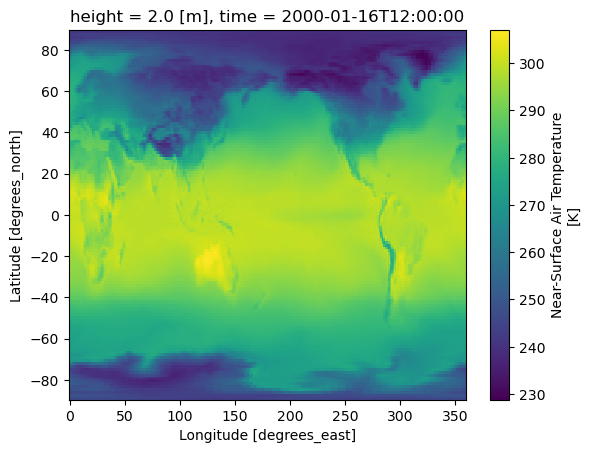

In [6]:
ds.tas.isel(time=0).plot()

## workflow: subset + regrid


In [2]:
tas = ops.Input(
    'tas', ['c3s-cmip6.CMIP.CNRM-CERFACS.CNRM-CM6-1.historical.r1i1p1f2.Amon.tas.gr.v20180917']
)

wf = ops.Subset(tas, time="2000-01/2000-01")

wf = ops.Regrid(wf, method="nearest_s2d", grid="1deg")

In [3]:
resp = wf.orchestrate()
resp.ok 

True

In [4]:
builtin_grid = download_result(resp)
builtin_grid

<xarray.Dataset> Size: 272kB
Dimensions:      (time: 1, lat: 180, lon: 360, bnds: 2, axis_nbounds: 2)
Coordinates:
  * time         (time) datetime64[ns] 8B 2000-01-16T12:00:00
  * lat          (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 87.5 88.5 89.5
  * lon          (lon) float64 3kB 0.5 1.5 2.5 3.5 ... 356.5 357.5 358.5 359.5
    lat_bnds     (lat, bnds) float64 3kB -90.0 -89.0 -89.0 ... 89.0 89.0 90.0
    lon_bnds     (lon, bnds) float64 6kB 0.0 1.0 1.0 2.0 ... 359.0 359.0 360.0
    time_bounds  (time, axis_nbounds) datetime64[ns] 16B 2000-01-01 2000-02-01
    height       float64 8B 2.0
Dimensions without coordinates: bnds, axis_nbounds
Data variables:
    tas          (time, lat, lon) float32 259kB 246.2 246.2 ... 241.0 241.0
Attributes: (12/59)
    name:                         /scratch/work/voldoire/outputs/CMIP6/DECK/C...
    Conventions:                  CF-1.7 CMIP-6.2
    creation_date:                2018-06-20T08:40:07Z
    description:                  CMIP6 historical
    title:                        CNRM-CM6-1 model output prepared for CMIP6 ...
    activity_id:                  CMIP
    ...                           ...
    grid_original:                data regridded to a T127 gaussian grid (128...
    grid_label_original:          gr
    nominal_resolution_original:  250 km
    regrid_operation:             nearest_s2d_128x256_180x360_peri
    regrid_tool:                  xESMF_v0.8.8
    regrid_weights_uid:           90229ccc58a26ce268bc1fc5d0f7414a_d24f4f689f...

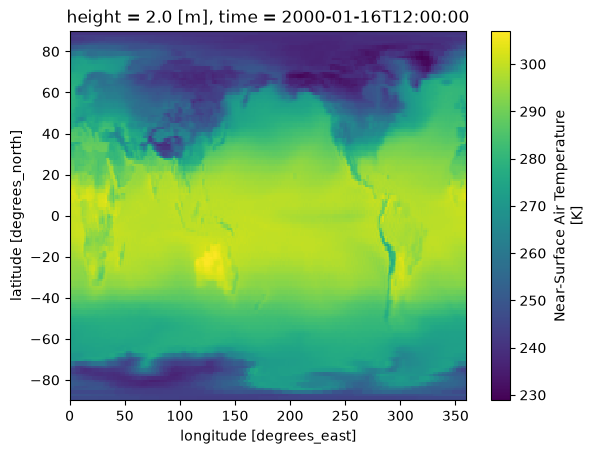

In [5]:
builtin_grid.tas.isel(time=0).plot()

## workflow: subset + regrid with custom_grid

In this Rook interface, custom grids are **regular latitude-longitude grids**. With `grid='custom'`, `custom_grid` sets the spacing in degrees and can also specify the geographical extent; it does not define an arbitrary projection, rotated grid or irregular ocean mesh, or accept an uploaded grid file.

| `custom_grid` | Target grid |
| --- | --- |
| `'1'` | Global grid with 1-degree spacing in both directions, matching the built-in `1deg` example above. |
| `'0.5'` | Global grid with 0.5-degree spacing in both directions. |
| `'0.5 0.25'` | Global grid with 0.5-degree longitude spacing and 0.25-degree latitude spacing. |
| `'-10 30 0.25 35 70 0.25'` | Longitude -10 to 30 degrees and latitude 35 to 70 degrees, with 0.25-degree spacing in both directions. The order is `lon_start lon_end lon_step lat_start lat_end lat_step`. |


Source: [Rook's live regrid input description](http://rook.dkrz.de/wps?service=WPS&version=1.0.0&request=DescribeProcess&identifier=regrid).

The following request uses the same source, month, method and **1-degree resolution** as the built-in example. The returned longitude conventions may differ: 0 to 360 degrees and -180 to 180 degrees place the map seam differently but can describe the same physical grid.

The comparison shows both fields using their returned longitudes and a shared temperature scale. It then wraps longitude into [-180, 180), sorts the columns and requires exactly matching coordinates before computing differences. This changes coordinate labels and order only; it does not interpolate the data. The table reports the actual returned coordinates, missing-value disagreements and maximum absolute difference, rather than assuming the fields are identical.

In [6]:
tas = ops.Input(
    'tas', ['c3s-cmip6.CMIP.CNRM-CERFACS.CNRM-CM6-1.historical.r1i1p1f2.Amon.tas.gr.v20180917']
)

wf = ops.Subset(tas, time="2000-01/2000-01")

wf = ops.Regrid(wf, method="nearest_s2d", grid="custom", custom_grid="1")

In [7]:
resp = wf.orchestrate()
resp.ok 

True

In [8]:
custom_grid = download_result(resp)
custom_grid

<xarray.Dataset> Size: 272kB
Dimensions:      (time: 1, lat: 180, lon: 360, bnds: 2, axis_nbounds: 2)
Coordinates:
  * time         (time) datetime64[ns] 8B 2000-01-16T12:00:00
  * lat          (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 87.5 88.5 89.5
  * lon          (lon) float64 3kB -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
    lat_bnds     (lat, bnds) float64 3kB -90.0 -89.0 -89.0 ... 89.0 89.0 90.0
    lon_bnds     (lon, bnds) float64 6kB -180.0 -179.0 -179.0 ... 179.0 180.0
    time_bounds  (time, axis_nbounds) datetime64[ns] 16B 2000-01-01 2000-02-01
    height       float64 8B 2.0
Dimensions without coordinates: bnds, axis_nbounds
Data variables:
    tas          (time, lat, lon) float32 259kB 243.8 243.8 ... 239.6 239.6
Attributes: (12/59)
    name:                         /scratch/work/voldoire/outputs/CMIP6/DECK/C...
    Conventions:                  CF-1.7 CMIP-6.2
    creation_date:                2018-06-20T08:40:07Z
    description:                  CMIP6 historical
    title:                        CNRM-CM6-1 model output prepared for CMIP6 ...
    activity_id:                  CMIP
    ...                           ...
    grid_original:                data regridded to a T127 gaussian grid (128...
    grid_label_original:          gr
    nominal_resolution_original:  250 km
    regrid_operation:             nearest_s2d_128x256_180x360_peri
    regrid_tool:                  xESMF_v0.9.2
    regrid_weights_uid:           90229ccc58a26ce268bc1fc5d0f7414a_ff485fa62d...

,longitude_min,longitude_max,latitude_min,latitude_max,longitude_cells,latitude_cells
grid,,,,,,
Built-in 1deg,0.5,359.5,-89.5,89.5,360,180
Custom 1 degree,-179.5,179.5,-89.5,89.5,360,180


,comparison,common_valid_cells,finite_mask_disagreements,max_absolute_difference,units
0,"custom - built-in, after longitude alignment",64800,0,0.0,K


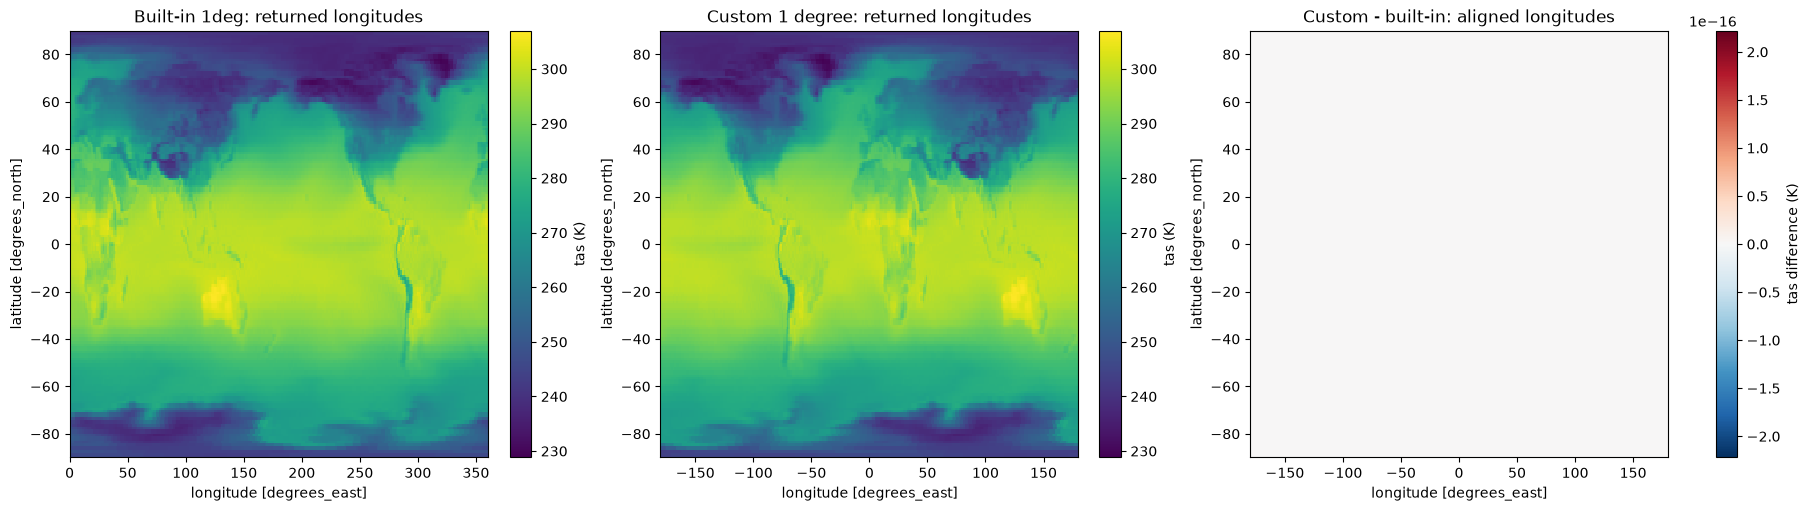

In [9]:
fields = {
    'Built-in 1deg': builtin_grid.tas.isel(time=0),
    'Custom 1 degree': custom_grid.tas.isel(time=0),
}
coordinate_rows = []
for name, field in fields.items():
    np.testing.assert_allclose(np.diff(field.lon), 1, rtol=0, atol=1e-8)
    np.testing.assert_allclose(np.diff(field.lat), 1, rtol=0, atol=1e-8)
    if field.sizes['lon'] != 360 or field.sizes['lat'] != 180:
        raise ValueError(f'{name}: expected a global 1-degree grid')
    coordinate_rows.append({
        'grid': name,
        'longitude_min': float(field.lon.min()),
        'longitude_max': float(field.lon.max()),
        'latitude_min': float(field.lat.min()),
        'latitude_max': float(field.lat.max()),
        'longitude_cells': field.sizes['lon'],
        'latitude_cells': field.sizes['lat'],
    })
display(pd.DataFrame(coordinate_rows).set_index('grid'))

def wrap_longitude(field):
    return field.assign_coords(lon=(field.lon + 180) % 360 - 180).sortby('lon')

builtin_aligned, custom_aligned = xr.align(
    wrap_longitude(fields['Built-in 1deg']),
    wrap_longitude(fields['Custom 1 degree']),
    join='exact',
)
units = builtin_aligned.attrs.get('units')
if not units or custom_aligned.attrs.get('units') != units:
    raise ValueError('Built-in and custom fields have missing or different units')
common = np.isfinite(builtin_aligned) & np.isfinite(custom_aligned)
if not bool(common.any()):
    raise ValueError('No common valid cells to compare')
difference = (custom_aligned - builtin_aligned).where(common)
display(pd.DataFrame([{
    'comparison': 'custom - built-in, after longitude alignment',
    'common_valid_cells': int(common.sum()),
    'finite_mask_disagreements': int(
        (np.isfinite(custom_aligned) != np.isfinite(builtin_aligned)).sum()
    ),
    'max_absolute_difference': float(abs(difference).max()),
    'units': units,
}]))

vmin = min(float(field.min()) for field in fields.values())
vmax = max(float(field.max()) for field in fields.values())
figure, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
for axis, (name, field) in zip(axes[:2], fields.items()):
    axis.set_facecolor('lightgrey')
    field.plot(ax=axis, vmin=vmin, vmax=vmax, cmap='viridis',
               cbar_kwargs={'label': f'tas ({units})'})
    axis.set_title(f'{name}: returned longitudes')
limit = max(float(abs(difference).max()), np.finfo(float).eps)
axes[2].set_facecolor('lightgrey')
difference.plot(ax=axes[2], cmap='RdBu_r', vmin=-limit, vmax=limit,
                cbar_kwargs={'label': f'tas difference ({units})'})
axes[2].set_title('Custom - built-in: aligned longitudes')
plt.show()

## Regridding method comparison

The project deliverables *Update WPS operations with regridding for CMIP5 & CMIP6* (D.2.1.10) and *Update WPS with full regridding operations for CORDEX* (D.2.1.11) describe regridding methods and robustness improvements. D.2.1.10 lists four methods: `nearest_s2d`, `bilinear`, `conservative`, and `patch`. This first comparison holds the CMIP6 input, January 2000 time subset, and `1deg` target grid constant so only the method changes. The custom-grid example above remains a separate test.

### What the methods do

| Method | How it works | Useful to know |
| --- | --- | --- |
| `nearest_s2d` | Each target point takes the value of its nearest source point. | Fast and preserves source values, so it can be useful for categories; fields may look blocky and it does not conserve area integrals. |
| `bilinear` | Interpolates between neighbouring source points using their relative positions (typically four points on a structured grid). | Produces smooth fields and is often useful for continuous variables such as temperature, but does not conserve area integrals. |
| `conservative` | Weights source-cell values by their overlap with each target cell. | Designed to preserve the area-integrated field when grids, domains and masks are handled consistently. It is often useful when coarsening gridded fields, but requires cell bounds and is sensitive to problematic cell geometry. |
| `patch` | Uses a higher-order polynomial fit over a neighbourhood of source points. | Produces smooth fields but can overshoot the source range, is generally slower, and is not conservative. |

Missing values and masks affect which source values contribute, so methods can produce different coverage near coastlines. In the plots below, grey indicates missing output, not a separately interpolated grey value.

Sources: [xESMF comparison of regridding algorithms](https://xesmf.readthedocs.io/en/latest/notebooks/Compare_algorithms.html) and [xESMF Regridder API, including bounds and missing-value handling](https://xesmf.readthedocs.io/en/latest/user_api.html#xesmf.frontend.Regridder). These describe xESMF generally; the Rook service may configure its masking differently.

The deliverable also lists predefined target grids `auto`, `0pt25deg`, `0pt25deg_era5`, `0pt5deg_lsm`, `0pt625x0pt5deg`, `0pt75deg`, `1deg`, `1pt25deg`, and `2pt5deg`. The ocean examples below also compare `0pt5deg_lsm` with a custom grid.

In [3]:
regrid_methods = ["nearest_s2d", "bilinear", "conservative", "patch"]
regrid_method_results = {}

for method in regrid_methods:
    workflow = ops.Regrid(
        ops.Subset(
            ops.Input(
                "tas",
                ["c3s-cmip6.CMIP.CNRM-CERFACS.CNRM-CM6-1.historical.r1i1p1f2.Amon.tas.gr.v20180917"],
            ),
            time="2000-01/2000-01",
        ),
        method=method,
        grid="1deg",
    )
    response = workflow.orchestrate()
    if not response.ok:
        raise RuntimeError(f"Regrid failed for method={method}")
    result = download_result(response)
    regrid_method_results[method] = result
    print(f"{method}: shape={result.tas.shape}, dims={result.tas.dims}")

## Pairwise differences between methods

For each method pair, the difference is calculated as the first method minus the second. Coordinates must match exactly; statistics use only non-missing values. The table reports signed mean difference, mean absolute difference, RMSE, and maximum absolute difference. The maps use a shared symmetric color scale.

For the `tas` run above, all difference statistics and map color bars are in K.

,valid_cells,mean_difference,mean_absolute_difference,rmse,maximum_absolute_difference
comparison,,,,,
nearest_s2d - bilinear,64800,-0.025268,0.415424,0.797878,12.295212
nearest_s2d - conservative,64800,-0.027444,0.311075,0.679598,11.177811
nearest_s2d - patch,64800,-0.024719,0.430241,0.809963,12.071625
bilinear - conservative,64800,-0.002176,0.120720,0.235657,5.321686
bilinear - patch,64800,0.000549,0.045478,0.100776,2.516296
conservative - patch,64800,0.002725,0.142923,0.272188,5.712585


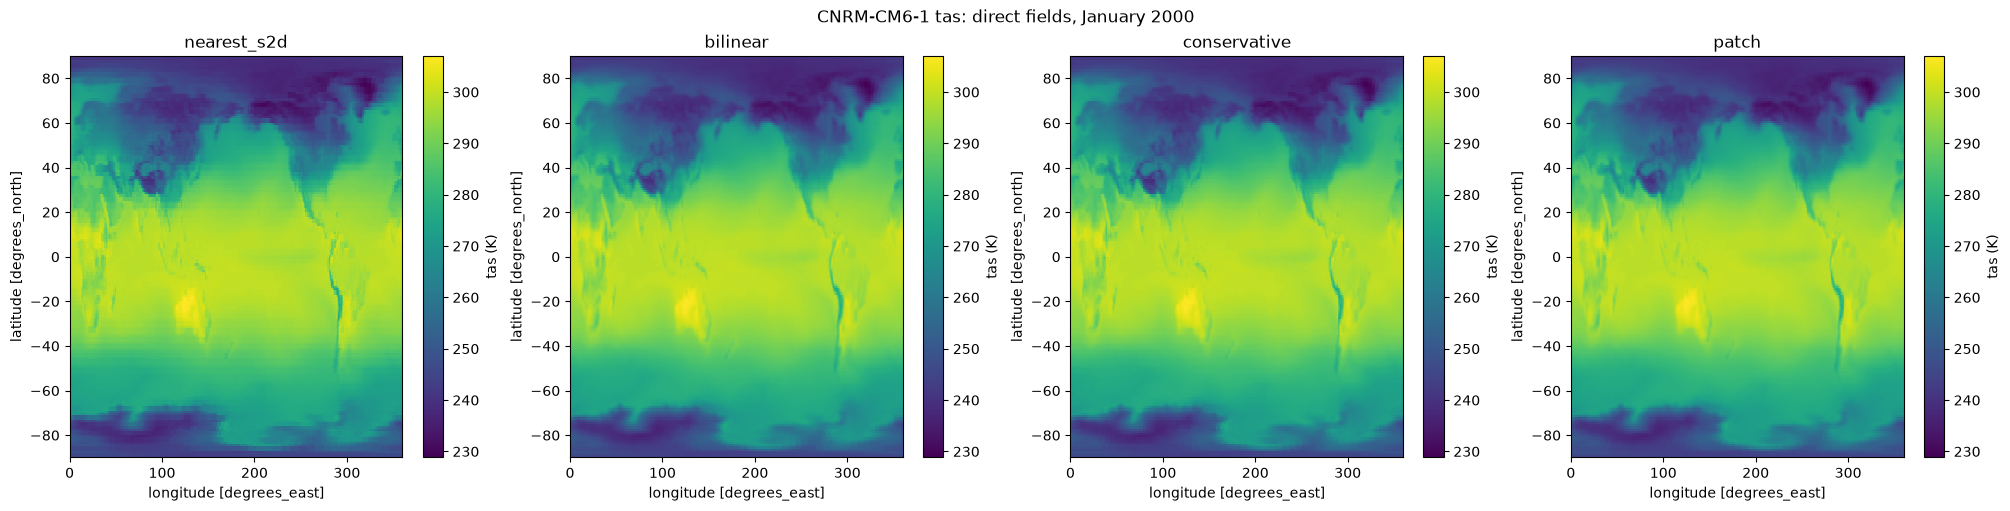

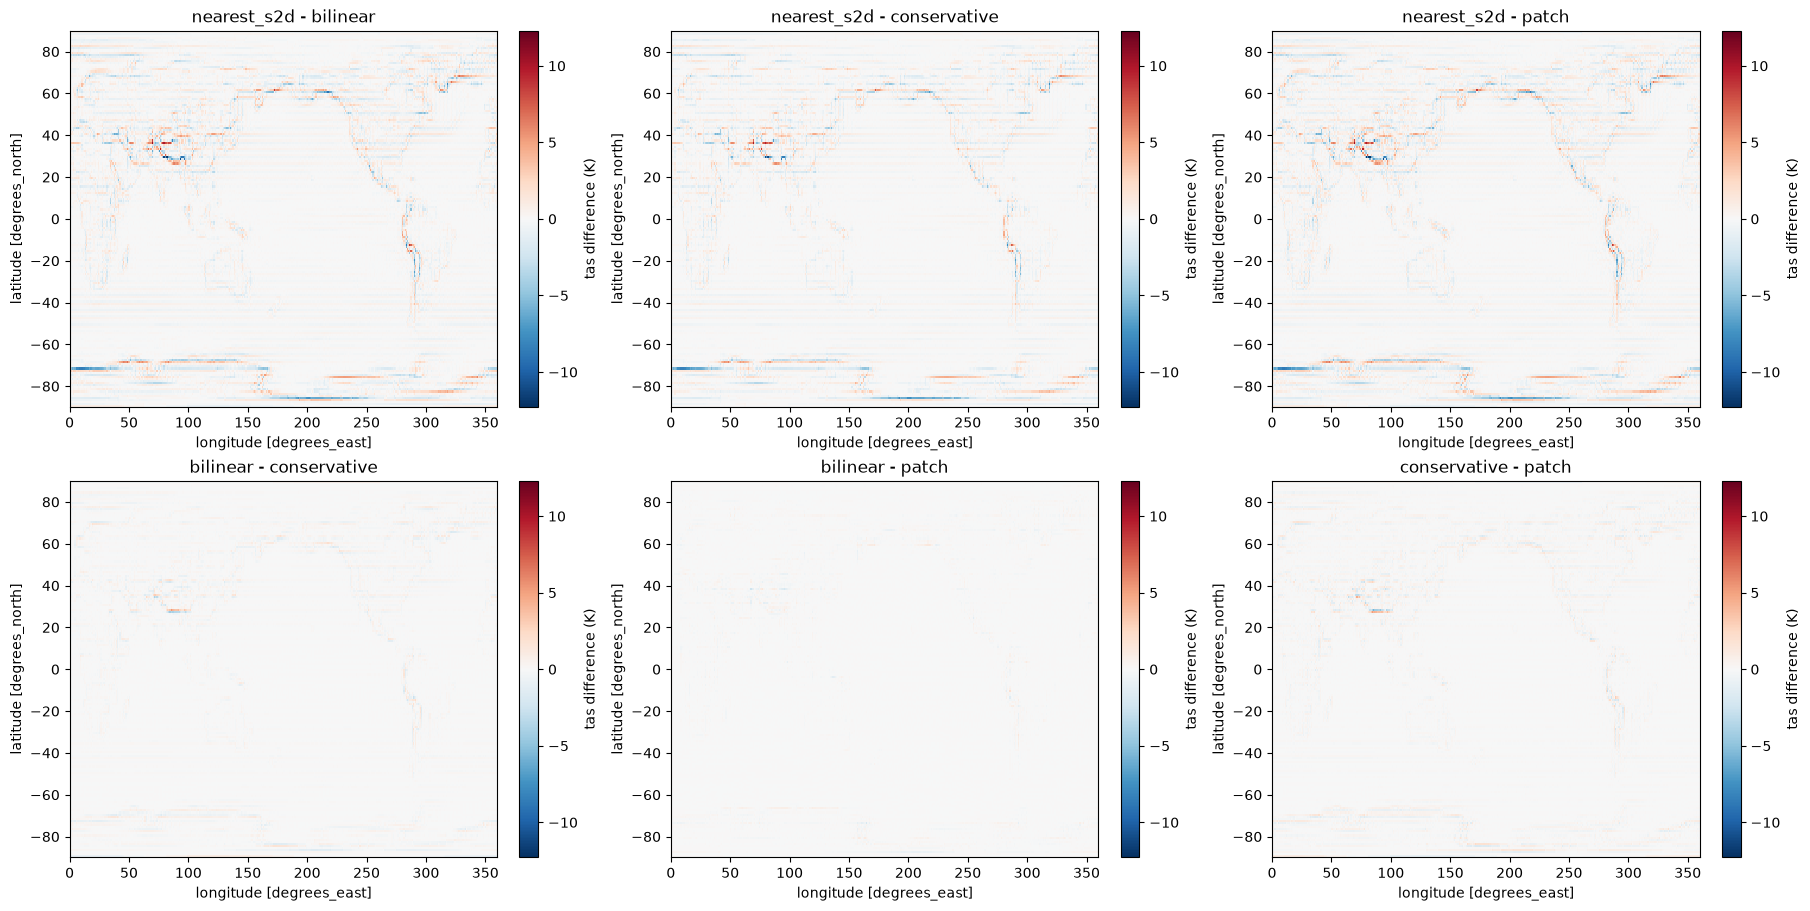

In [7]:
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr

difference_fields = {}
difference_rows = []

for method_a, method_b in combinations(regrid_methods, 2):
    field_a, field_b = xr.align(
        regrid_method_results[method_a]["tas"],
        regrid_method_results[method_b]["tas"],
        join="exact",
    )
    units_a = field_a.attrs.get("units", "")
    units_b = field_b.attrs.get("units", "")
    if units_a != units_b:
        raise ValueError(f"Unit mismatch: {method_a}={units_a!r}, {method_b}={units_b!r}")
    difference = field_a - field_b
    valid_cells = int(difference.count().item())
    if valid_cells == 0:
        raise ValueError(f"No valid overlapping cells for {method_a} - {method_b}")
    label = f"{method_a} - {method_b}"
    difference_fields[label] = difference
    difference_rows.append(
        {
            "comparison": label,
            "valid_cells": valid_cells,
            "mean_difference": float(difference.mean(skipna=True).item()),
            "mean_absolute_difference": float(abs(difference).mean(skipna=True).item()),
            "rmse": float(np.sqrt((difference**2).mean(skipna=True)).item()),
            "maximum_absolute_difference": float(abs(difference).max(skipna=True).item()),
        }
    )

difference_summary = pd.DataFrame(difference_rows).set_index("comparison")
from IPython.display import display
display(difference_summary)

fields = [regrid_method_results[method]['tas'].isel(time=0) for method in regrid_methods]
field_min = min(float(field.min().item()) for field in fields)
field_max = max(float(field.max().item()) for field in fields)
figure, axes = plt.subplots(1, 4, figsize=(20, 5), constrained_layout=True)
for axis, method, field in zip(axes, regrid_methods, fields):
    axis.set_facecolor('lightgrey')
    field.plot(ax=axis, vmin=field_min, vmax=field_max,
               cbar_kwargs={'label': f'tas ({field.attrs.get("units")})'})
    axis.set_title(method)
figure.suptitle('CNRM-CM6-1 tas: direct fields, January 2000')
plt.show()

max_abs_difference = difference_summary["maximum_absolute_difference"].max()
color_limit = max(float(max_abs_difference), np.finfo(float).eps)
units = regrid_method_results[regrid_methods[0]]["tas"].attrs.get("units", "source units")
figure, axes = plt.subplots(2, 3, figsize=(18, 9), constrained_layout=True)
for axis, (label, difference) in zip(axes.flat, difference_fields.items()):
    difference.isel(time=0).plot(
        ax=axis,
        cmap="RdBu_r",
        vmin=-color_limit,
        vmax=color_limit,
        cbar_kwargs={"label": f"tas difference ({units})"},
    )
    axis.set_title(label)
plt.show()

## Additional model and variable tests

To check whether the method behavior is specific to the CNRM atmospheric `tas` example, the same four methods and `1deg` target are applied to MIROC `tas`, SAM0-UNICON daily `pr`, and NorESM2-MM ocean `tos`. Each request uses a short period.

In [3]:
additional_regrid_cases = {}

def test_regrid_case(case_name, variable, dataset_id, time_range, grid="1deg"):
    case = {
        "variable": variable,
        "dataset_id": dataset_id,
        "time_range": time_range,
        "results": {},
    }
    additional_regrid_cases[case_name] = case
    for method in regrid_methods:
        print(f"Running {case_name}: {method}")
        workflow = ops.Regrid(
            ops.Subset(
                ops.Input(variable, [dataset_id]),
                time=time_range,
            ),
            method=method,
            grid=grid,
        )
        response = workflow.orchestrate()
        if not response.ok:
            raise RuntimeError(f"Regrid failed for {case_name}, method={method}")
        result = download_result(response)
        case["results"][method] = result
        print(f"  shape={result[variable].shape}, dims={result[variable].dims}")
    return case["results"]

In [4]:
miroc_tas_results = test_regrid_case(
    "MIROC-ES2H tas",
    "tas",
    "c3s-cmip6.CMIP.MIROC.MIROC-ES2H.historical.r1i1p4f2.Amon.tas.gn.v20220322",
    "2000-01/2000-01",
)

In [5]:
sam0_pr_results = test_regrid_case(
    "SAM0-UNICON pr",
    "pr",
    "c3s-cmip6.CMIP.SNU.SAM0-UNICON.historical.r1i1p1f1.day.pr.gn.v20190323",
    "1850-01-01/1850-01-01",
)

In [6]:
noresm_tos_results = test_regrid_case(
    "NorESM2-MM tos",
    "tos",
    "c3s-cmip6.ScenarioMIP.NCC.NorESM2-MM.ssp245.r1i1p1f1.Omon.tos.gn.v20191108",
    "2050-04/2050-04",
)

In [7]:
from itertools import combinations
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

additional_difference_rows = []
for case_name, case in additional_regrid_cases.items():
    methods_available = [method for method in regrid_methods if method in case["results"]]
    for method_a, method_b in combinations(methods_available, 2):
        field_a, field_b = xr.align(
            case["results"][method_a][case["variable"]],
            case["results"][method_b][case["variable"]],
            join="exact",
        )
        units_a = field_a.attrs.get("units", "")
        units_b = field_b.attrs.get("units", "")
        if units_a != units_b:
            raise ValueError(f"Unit mismatch for {case_name}: {units_a!r} vs {units_b!r}")
        difference = field_a - field_b
        valid_cells = int(difference.count().item())
        if valid_cells == 0:
            raise ValueError(f"No valid overlapping cells for {case_name}: {method_a} - {method_b}")
        additional_difference_rows.append(
            {
                "case": case_name,
                "variable": case["variable"],
                "comparison": f"{method_a} - {method_b}",
                "units": units_a,
                "valid_cells": valid_cells,
                "mean_difference": float(difference.mean(skipna=True).item()),
                "mean_absolute_difference": float(abs(difference).mean(skipna=True).item()),
                "rmse": float(np.sqrt((difference**2).mean(skipna=True)).item()),
                "maximum_absolute_difference": float(abs(difference).max(skipna=True).item()),
            }
        )

if not additional_difference_rows:
    raise ValueError("No additional method pairs completed successfully")
additional_difference_summary = pd.DataFrame(additional_difference_rows)
display(additional_difference_summary)

,case,variable,comparison,units,valid_cells,mean_difference,mean_absolute_difference,rmse,maximum_absolute_difference
0,MIROC-ES2H tas,tas,nearest_s2d - bilinear,K,64800,-1.842048e-02,3.218227e-01,0.568920,10.124115
1,MIROC-ES2H tas,tas,nearest_s2d - conservative,K,64800,-2.264954e-02,2.416860e-01,0.481055,9.293915
2,MIROC-ES2H tas,tas,nearest_s2d - patch,K,64800,-1.841358e-02,3.270642e-01,0.570936,9.974609
3,MIROC-ES2H tas,tas,bilinear - conservative,K,64800,-4.229057e-03,9.633103e-02,0.175184,2.947083
4,MIROC-ES2H tas,tas,bilinear - patch,K,64800,6.903189e-06,2.524914e-02,0.051733,0.989136
5,MIROC-ES2H tas,tas,conservative - patch,K,64800,4.235961e-03,1.054085e-01,0.187038,2.966400
6,SAM0-UNICON pr,pr,nearest_s2d - bilinear,kg m-2 s-1,64800,-1.887721e-07,4.073967e-06,0.000015,0.000614
7,SAM0-UNICON pr,pr,nearest_s2d - conservative,kg m-2 s-1,64800,-1.983236e-07,4.021303e-06,0.000015,0.000594
8,SAM0-UNICON pr,pr,nearest_s2d - patch,kg m-2 s-1,64800,-1.943417e-07,4.213664e-06,0.000015,0.000604
9,SAM0-UNICON pr,pr,bilinear - conservative,kg m-2 s-1,64800,-9.551490e-09,3.536522e-07,0.000001,0.000077


## Difference maps for additional models

Each comparison first shows the direct field from every tested method on a shared scale, followed by pairwise difference maps (first method minus second). Direct fields use a common scale within each model; differences use a separate shared symmetric scale. Scales differ between models and variables. Grey denotes missing values. Fixed fields are plotted directly; time-varying fields use the first time step. The earlier test cells must run first.

In [7]:
def plot_case_differences(case_name, native_field=None):
    case = additional_regrid_cases[case_name]
    variable = case["variable"]
    methods = case.get('methods', regrid_methods)
    missing = [method for method in methods if method not in case["results"]]
    if missing:
        raise ValueError(f"{case_name}: missing method results: {missing}")

    fields = [case['results'][method][variable] for method in methods]
    units = fields[0].attrs.get('units')
    if not units or any(field.attrs.get('units') != units for field in fields):
        raise ValueError(f'{case_name}: missing or mismatched field units')
    fields = [field.isel(time=0) if 'time' in field.dims else field for field in fields]
    if native_field is not None:
        native_field = native_field.isel(time=0) if 'time' in native_field.dims else native_field
        if native_field.attrs.get('units') != units:
            raise ValueError(f'{case_name}: native and regridded field units differ')
    scale_fields = fields + ([native_field] if native_field is not None else [])
    vmin = min(float(field.min(skipna=True).item()) for field in scale_fields)
    vmax = max(float(field.max(skipna=True).item()) for field in scale_fields)
    panel_count = len(methods) + (native_field is not None)
    figure, axes = plt.subplots(1, panel_count, figsize=(5 * panel_count, 5), constrained_layout=True, squeeze=False)
    method_axes = axes.flat
    if native_field is not None:
        axis = axes.flat[0]
        axis.set_facecolor('lightgrey')
        longitude = np.mod(native_field.longitude.values, 360)
        latitude = native_field.latitude.values
        values = native_field.values
        valid = np.isfinite(longitude) & np.isfinite(latitude) & np.isfinite(values)
        points = axis.scatter(longitude[valid], latitude[valid], c=values[valid],
                              s=1, marker='s', vmin=vmin, vmax=vmax, cmap='viridis')
        figure.colorbar(points, ax=axis, label=f'{variable} ({units})')
        axis.set(xlim=(0, 360), ylim=(-90, 90), xlabel='longitude', ylabel='latitude',
                 title='native (source centres)')
        method_axes = axes.flat[1:]
    for axis, method, field in zip(method_axes, methods, fields):
        axis.set_facecolor('lightgrey')
        field.plot(ax=axis, vmin=vmin, vmax=vmax, cmap='viridis' if native_field is not None else None,
                   cbar_kwargs={'label': f'{variable} ({units})'})
        axis.set_title(method)
    figure.suptitle(f"{case_name}: direct fields, {case['time_range'] or 'fixed field'}")
    plt.show()

    differences = {}
    units = None
    for method_a, method_b in combinations(methods, 2):
        field_a, field_b = xr.align(
            case["results"][method_a][variable],
            case["results"][method_b][variable],
            join="exact",
        )
        units_a = field_a.attrs.get("units")
        units_b = field_b.attrs.get("units")
        if not units_a or units_a != units_b or (units is not None and units != units_a):
            raise ValueError(f"{case_name}: missing or mismatched units: {units_a!r}, {units_b!r}")
        units = units_a
        difference = field_a - field_b
        if 'time' in difference.dims:
            difference = difference.isel(time=0)
        if int(difference.count().item()) == 0:
            raise ValueError(f"{case_name}: no valid values for {method_a} - {method_b}")
        differences[f"{method_a} - {method_b}"] = difference

    limit = max(float(abs(field).max(skipna=True).item()) for field in differences.values())
    limit = max(limit, np.finfo(float).eps)
    figure, axes = plt.subplots(2, 3, figsize=(18, 9), constrained_layout=True)
    for axis, (label, difference) in zip(axes.flat, differences.items()):
        axis.set_facecolor("lightgrey")
        difference.plot(
            ax=axis, cmap="RdBu_r", vmin=-limit, vmax=limit,
            cbar_kwargs={"label": f"{variable} difference ({units})"},
        )
        axis.set_title(label)
    for axis in axes.flat[len(differences):]:
        axis.set_visible(False)
    figure.suptitle(f"{case_name}: {case['time_range'] or 'fixed field'}")
    plt.show()

In [4]:
ocean_cases = {
    'MPI-ESM1-2-LR tos': {
        'variable': 'tos', 'time_range': '2000-01/2000-01',
        'dataset_id': 'c3s-cmip6.CMIP.MPI-M.MPI-ESM1-2-LR.historical.r1i1p1f1.Omon.tos.gn.v20190710',
        'results': {},
    },
    'IITM-ESM tos': {
        'variable': 'tos', 'time_range': '2050-04/2050-04',
        'dataset_id': 'c3s-cmip6.ScenarioMIP.CCCR-IITM.IITM-ESM.ssp126.r1i1p1f1.Omon.tos.gn.v20201112',
        'results': {},
    },
}


def ocean_download(case_name, workflow):
    case = ocean_cases[case_name]
    dataset = download_result(workflow.orchestrate())
    field = dataset[case['variable']]
    if ('time' in field.dims and field.sizes['time'] != 1) or not bool(np.isfinite(field).any()):
        raise ValueError(f'{case_name}: expected a non-empty fixed field or single time slice')
    return dataset

def ocean_source_workflow(case_name):
    case = ocean_cases[case_name]
    source = ops.Input(case['variable'], [case['dataset_id']])
    if case['time_range'] is not None:
        source = ops.Subset(source, time=case['time_range'])
    else:
        source = ops.Subset(source)
    return source

def ocean_regrid(case_name, method, grid, custom_grid=None):
    parameters = {'method': method, 'grid': grid}
    if custom_grid is not None:
        parameters['custom_grid'] = custom_grid
    workflow = ops.Regrid(ocean_source_workflow(case_name), **parameters)
    return ocean_download(case_name, workflow)

def ocean_native(case_name):
    return ocean_download(case_name, ocean_source_workflow(case_name))

def test_ocean_case(case_name, include_native=False):
    case = ocean_cases[case_name]
    additional_regrid_cases[case_name] = case
    for method in regrid_methods:
        case['results'][method] = ocean_regrid(case_name, method, '1deg')
    display(pd.DataFrame([
        {'method': method, 'finite_cells': int(np.isfinite(ds.tos).sum().item()),
         'minimum': float(ds.tos.min().item()), 'maximum': float(ds.tos.max().item())}
        for method, ds in case['results'].items()
    ]))
    native_field = ocean_native(case_name)[case['variable']] if include_native else None
    plot_case_differences(case_name, native_field=native_field)

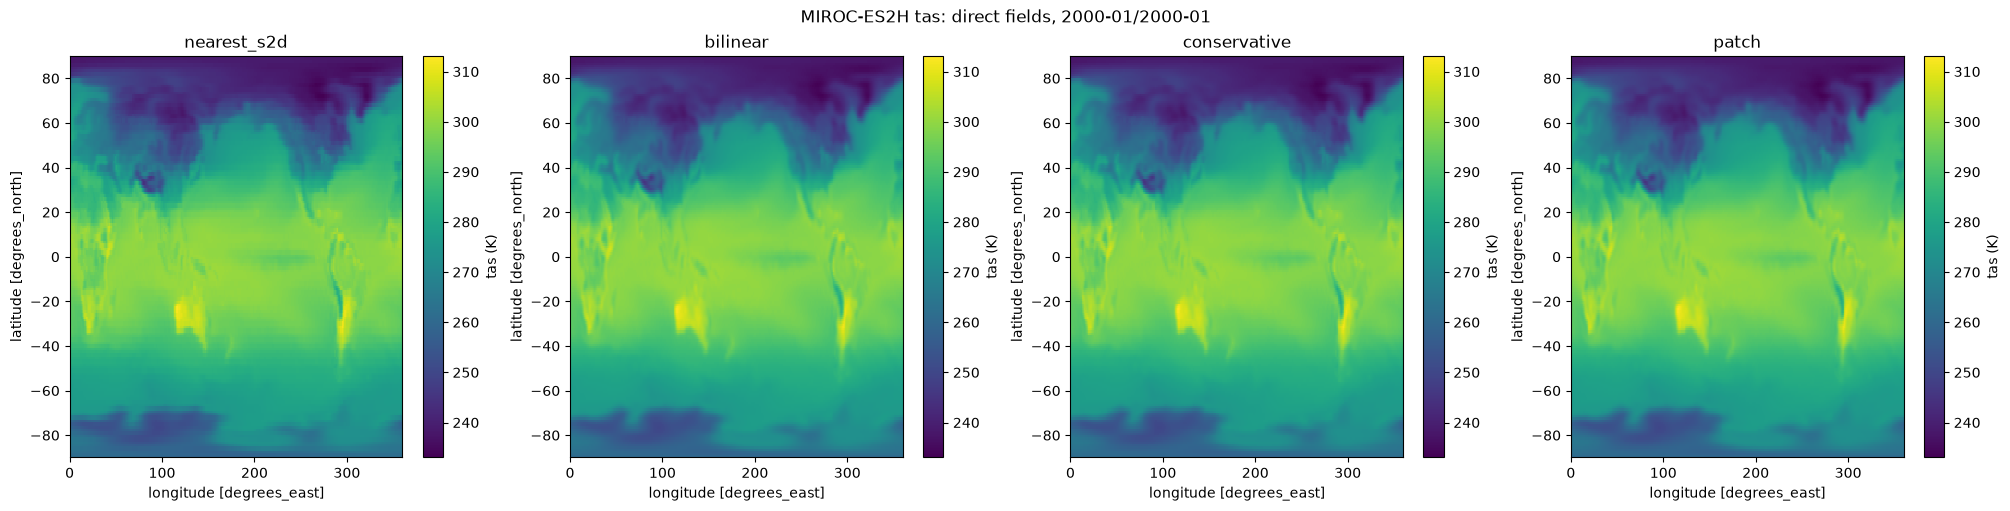

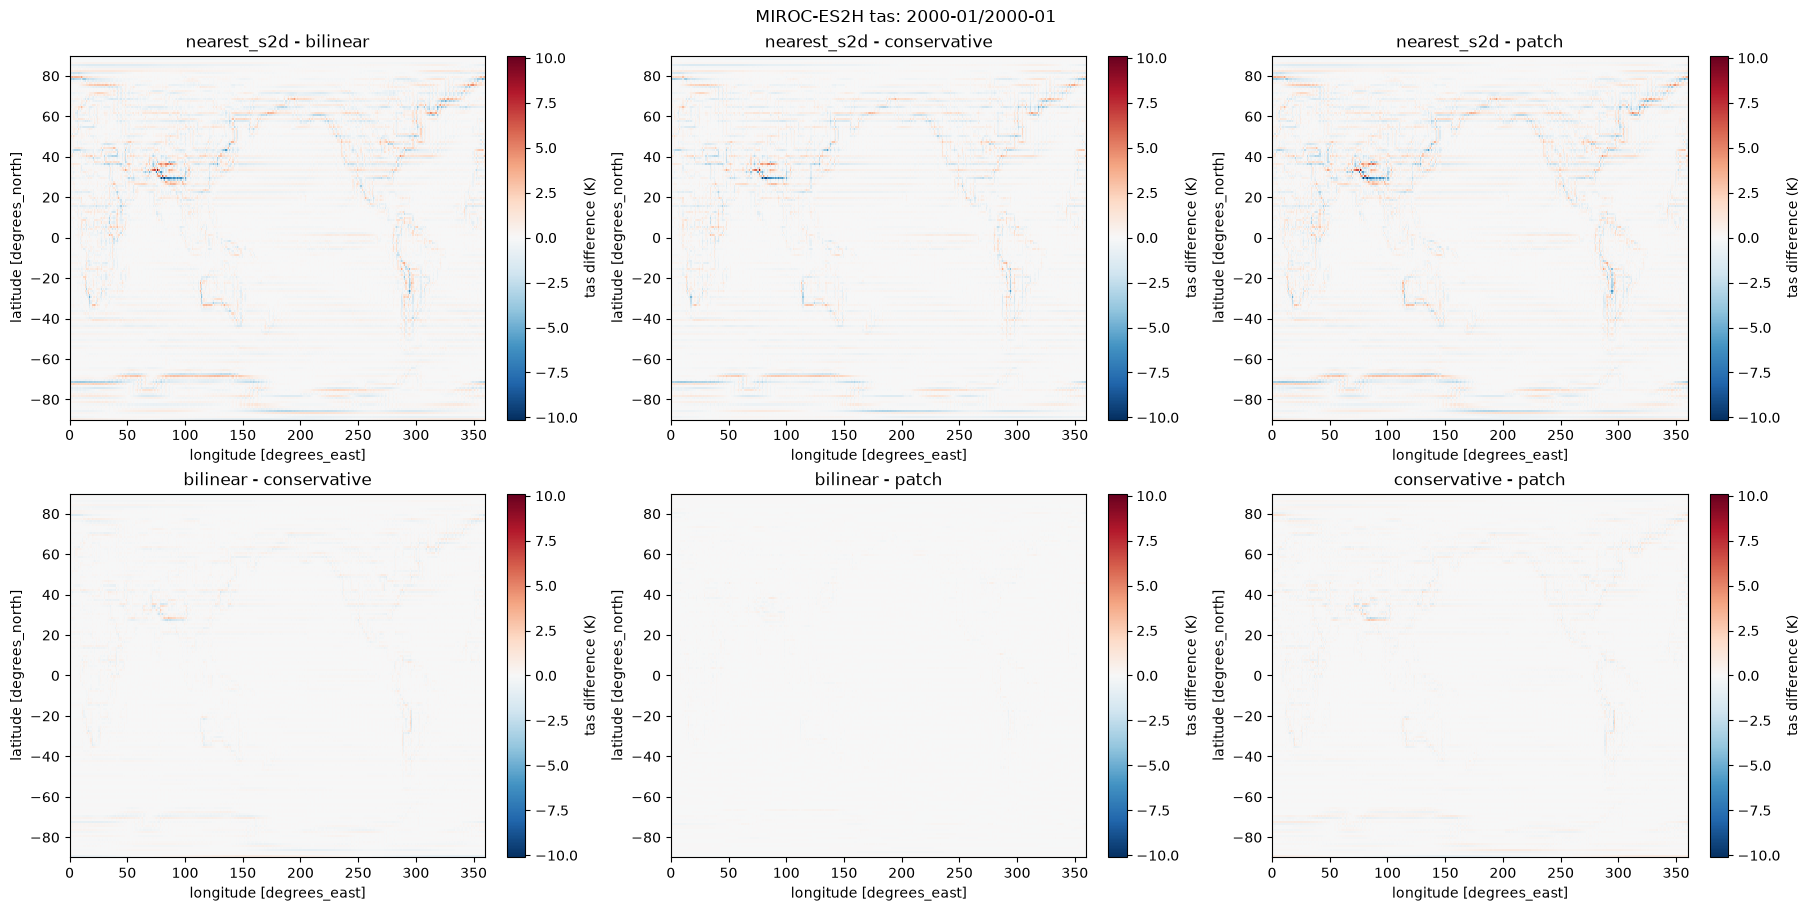

In [9]:
plot_case_differences("MIROC-ES2H tas")

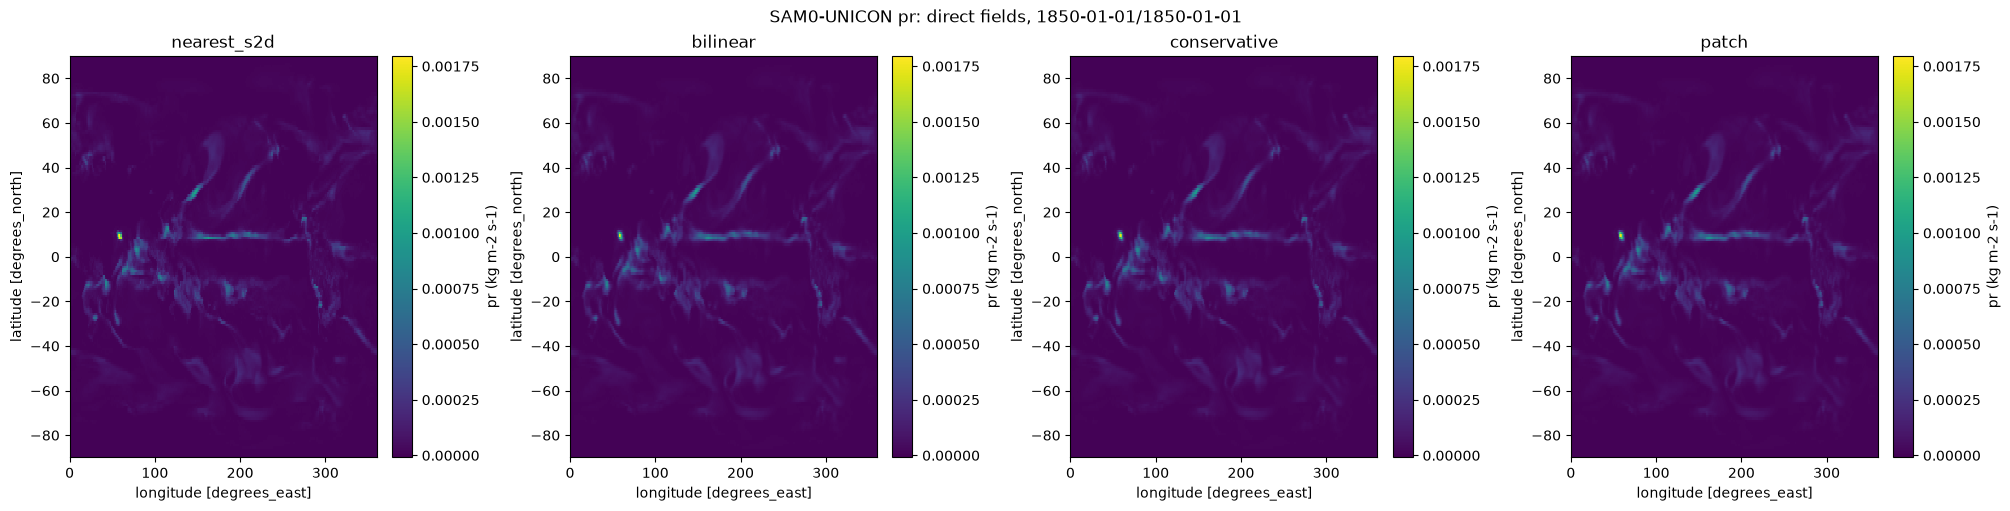

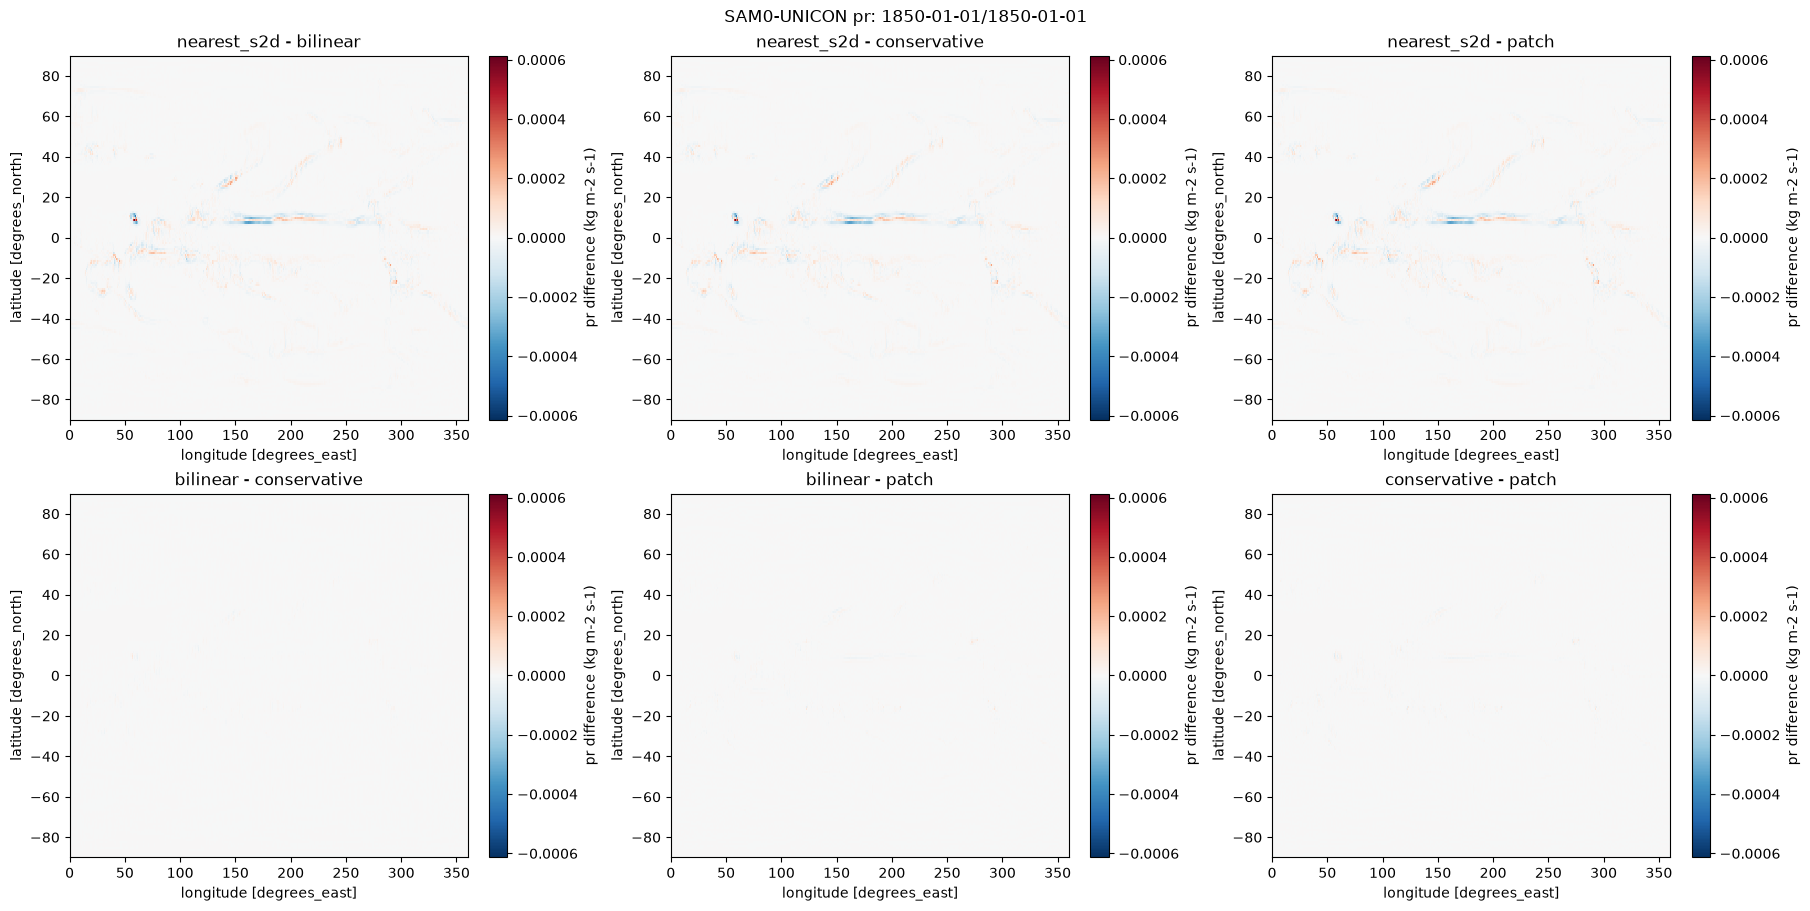

In [11]:
plot_case_differences("SAM0-UNICON pr")

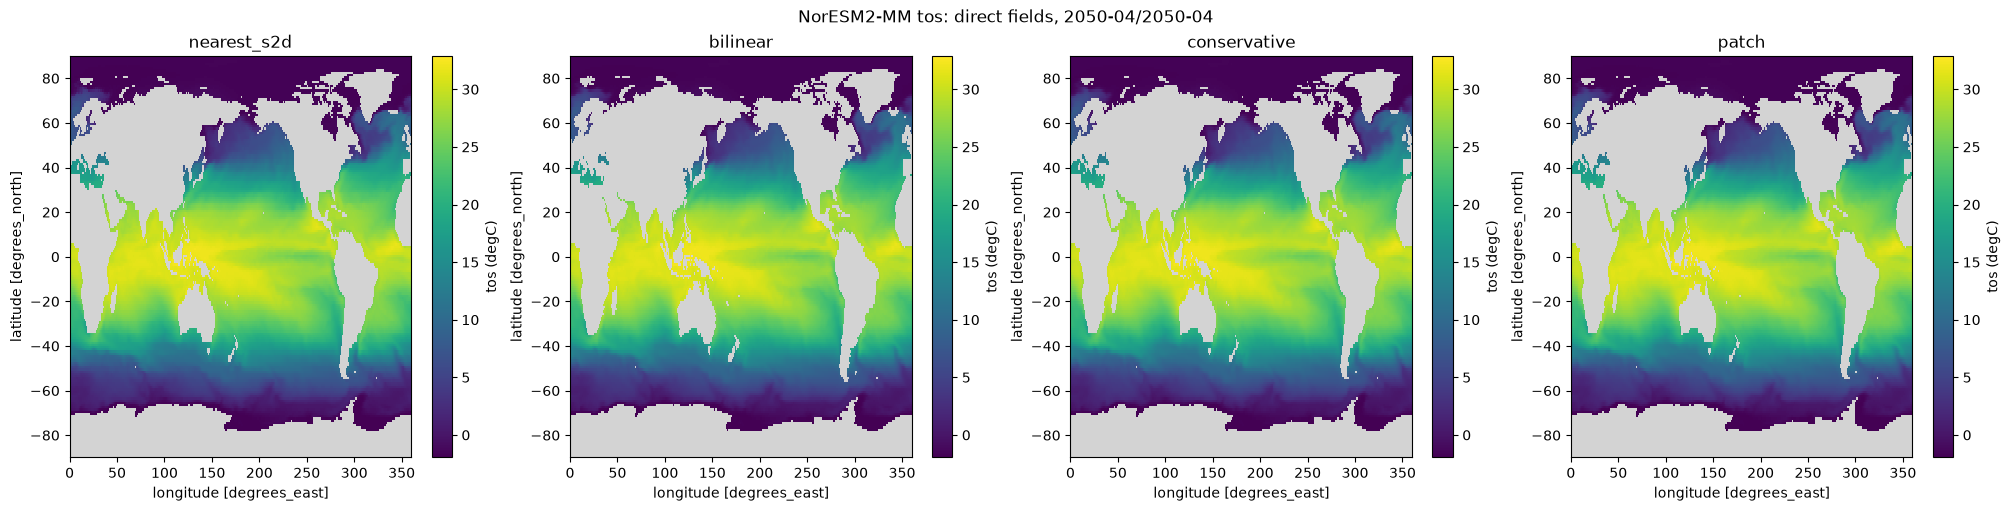

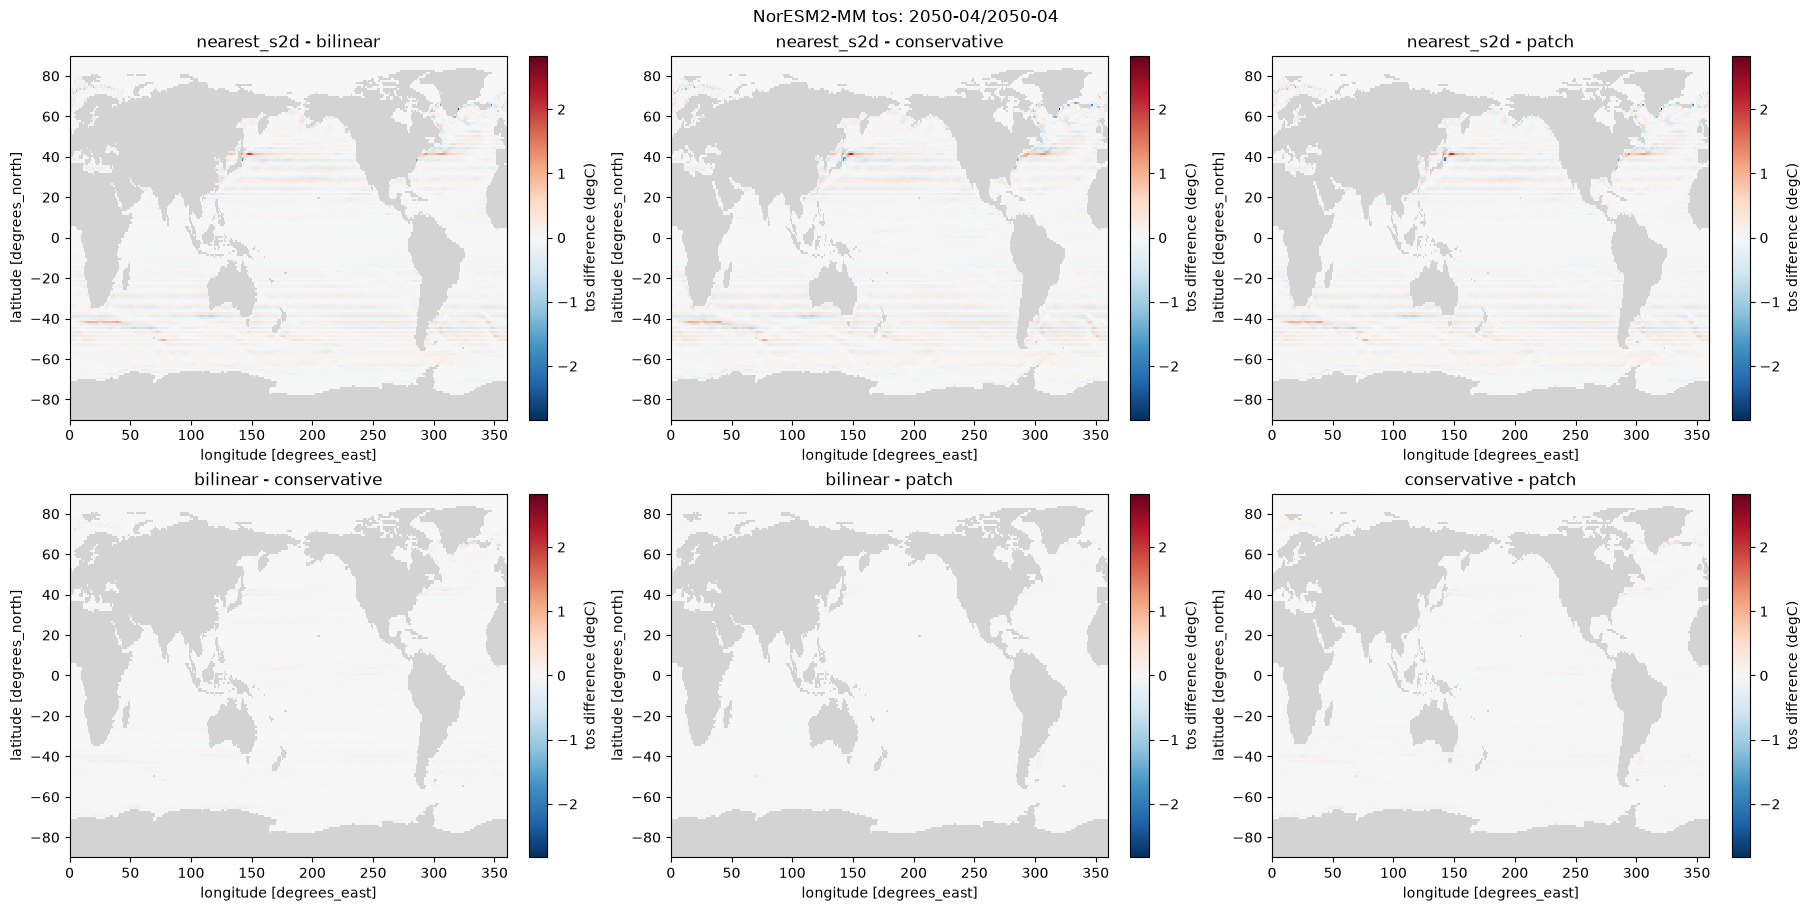

In [13]:
plot_case_differences("NorESM2-MM tos")

### Example: native IITM ocean data versus regridded fields

The left panel shows native-grid `tos` for April 2050 at its source-cell centres; the other panels show the four methods on the 1-degree target grid. All direct fields use the same temperature scale.

**Reading the polar region:** the native panel uses point markers, not filled cell polygons. Grey spaces can be gaps between markers rather than missing source temperatures. All native source points north of 85 degrees N are valid in this sample. In the regridded panels, grey indicates missing output. Nearest-neighbour can assign a nearby source value without surrounding source points, so solid polar coverage does not demonstrate greater accuracy.

The difference maps compare methods **on the common target grid**, not against the native grid. Conservative-remapping artifacts are documented for this model; missing values and geometry may both matter, and these plots alone do not prove the cause.

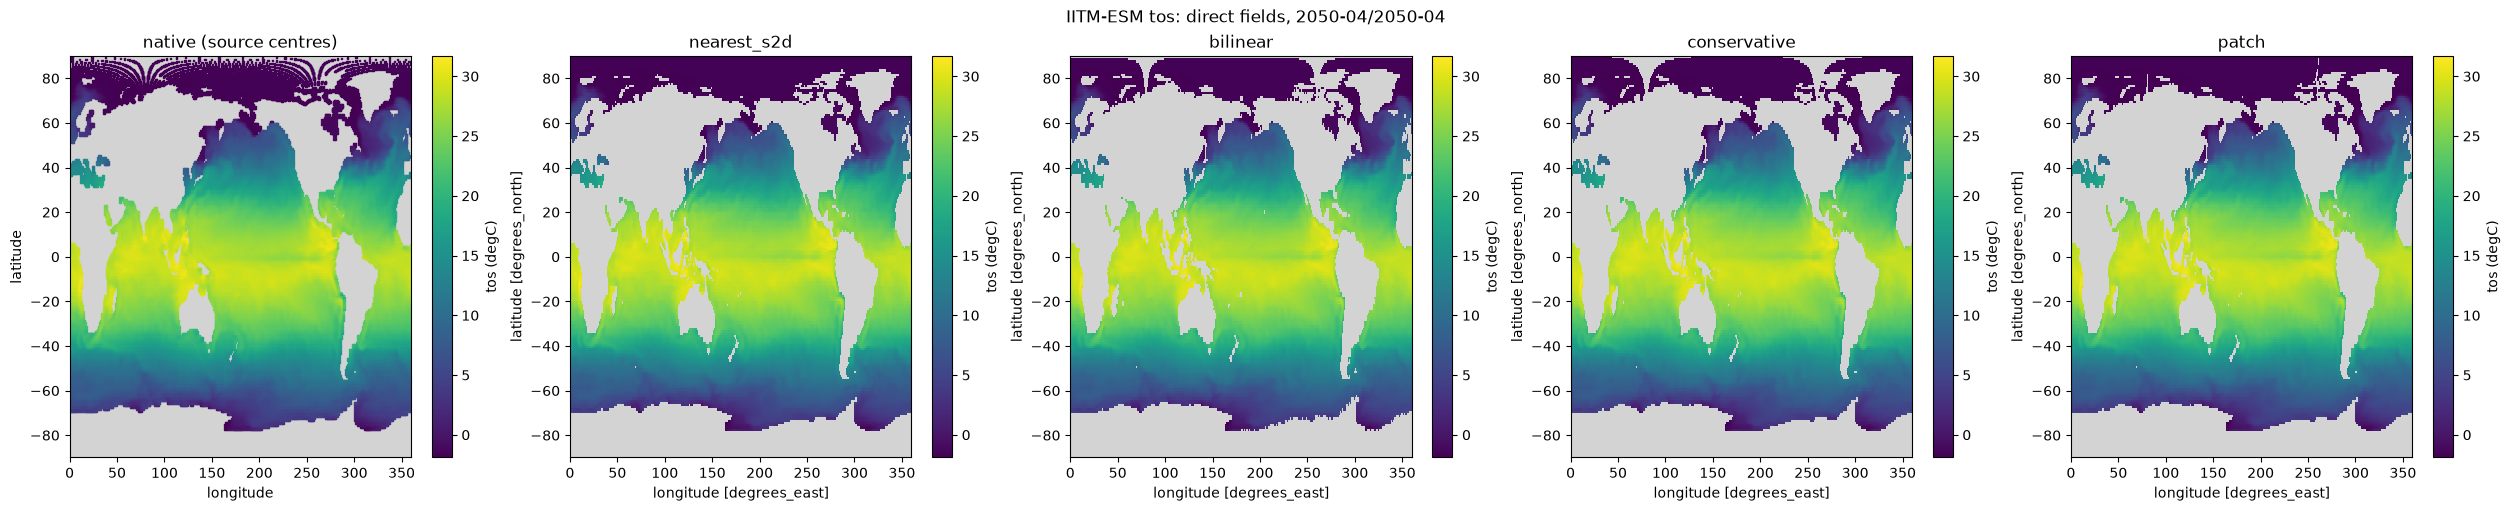

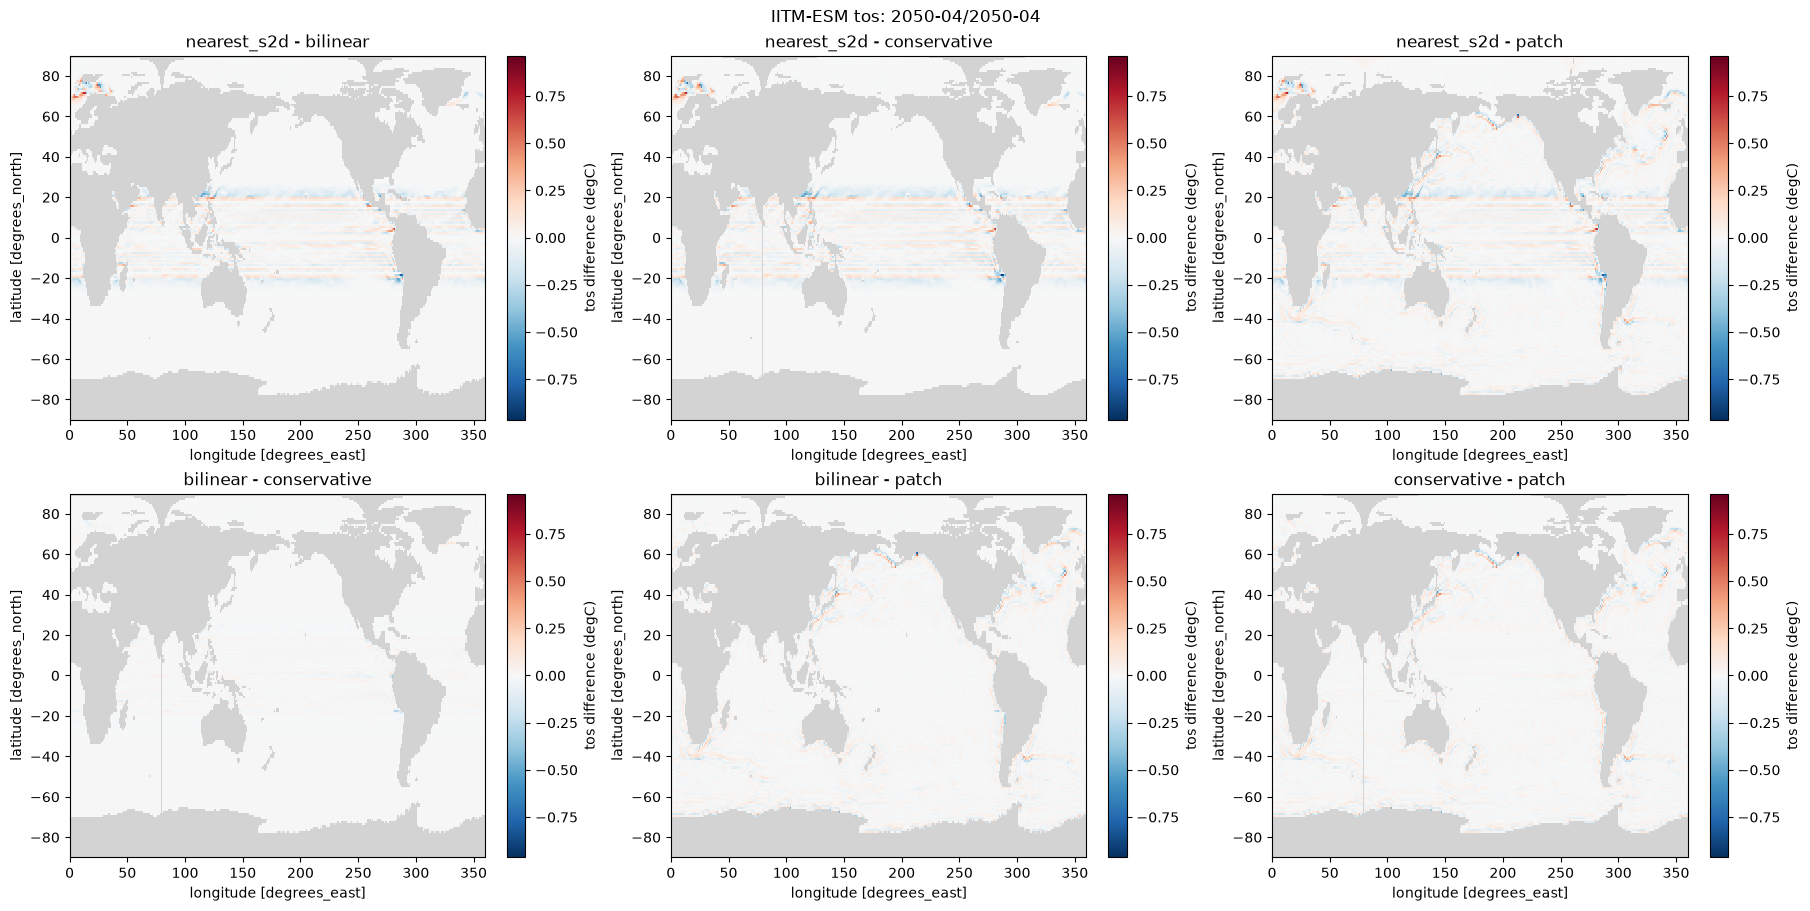

In [5]:
case_name = 'IITM-ESM tos'
case = ocean_cases[case_name]
native_iitm_tos = ocean_native(case_name)['tos']
for method in regrid_methods:
    case['results'][method] = ocean_regrid(case_name, method, '1deg')
additional_regrid_cases[case_name] = case
plot_case_differences(case_name, native_field=native_iitm_tos)


## Ocean-grid robustness and land-sea masks

Adaptive masking adjusts contributions from missing source values; a geographical land-sea mask excludes selected locations. These are different operations.

The MPI comparison includes the original native field beside the regridded fields on a shared scale. IITM's original field is shown in the earlier example and is not repeated here. Native fields use source-centre markers: grey space may be a gap between markers rather than missing data.

The tested Rook interface exposes `collection`, `method`, `grid` and `custom_grid`, but no mask selector or mask-file upload. Selecting `0pt5deg_lsm` alone does not demonstrate that a mask is applied. Named grids are resolved on the server; a custom grid specifies numeric geometry, not an uploaded file.

The tests compare MPI-ESM1-2-LR and IITM-ESM `tos`, then compare MPI nearest-neighbour on `0pt5deg_lsm` and an equivalent custom half-degree grid. A separately downloaded reference mask illustrates local post-masking. It is not sent to Rook, does not alter interpolation weights and cannot repair bad source-cell bounds.

Sources: [Rook inputs](http://rook.dkrz.de/wps?service=WPS&version=1.0.0&request=DescribeProcess&identifier=regrid), [Rook wrapper](https://github.com/roocs/rook/blob/main/src/rook/operations/regrid.py), [clisops masking](https://github.com/roocs/clisops/blob/master/clisops/ops/regrid.py), [reference grids and masks](https://github.com/roocs/roocs-grids). Source code does not establish which backend version the service deploys.

,method,finite_cells,minimum,maximum
0,nearest_s2d,42679,-1.900000,31.807280
1,bilinear,40502,-1.900000,31.002617
2,conservative,42720,-1.900000,31.807280
3,patch,42716,-1.995098,31.645586


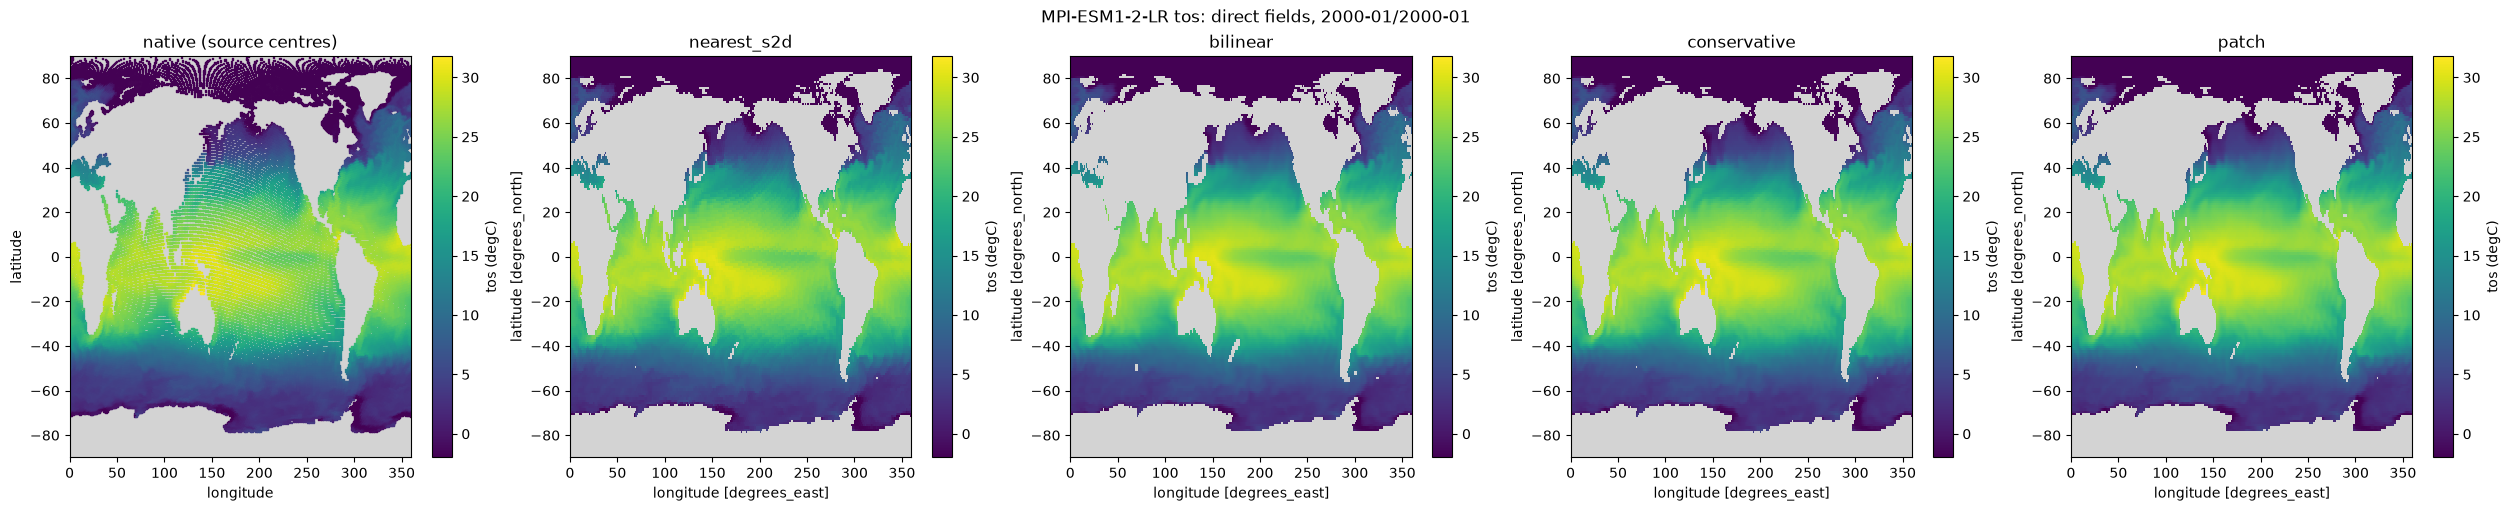

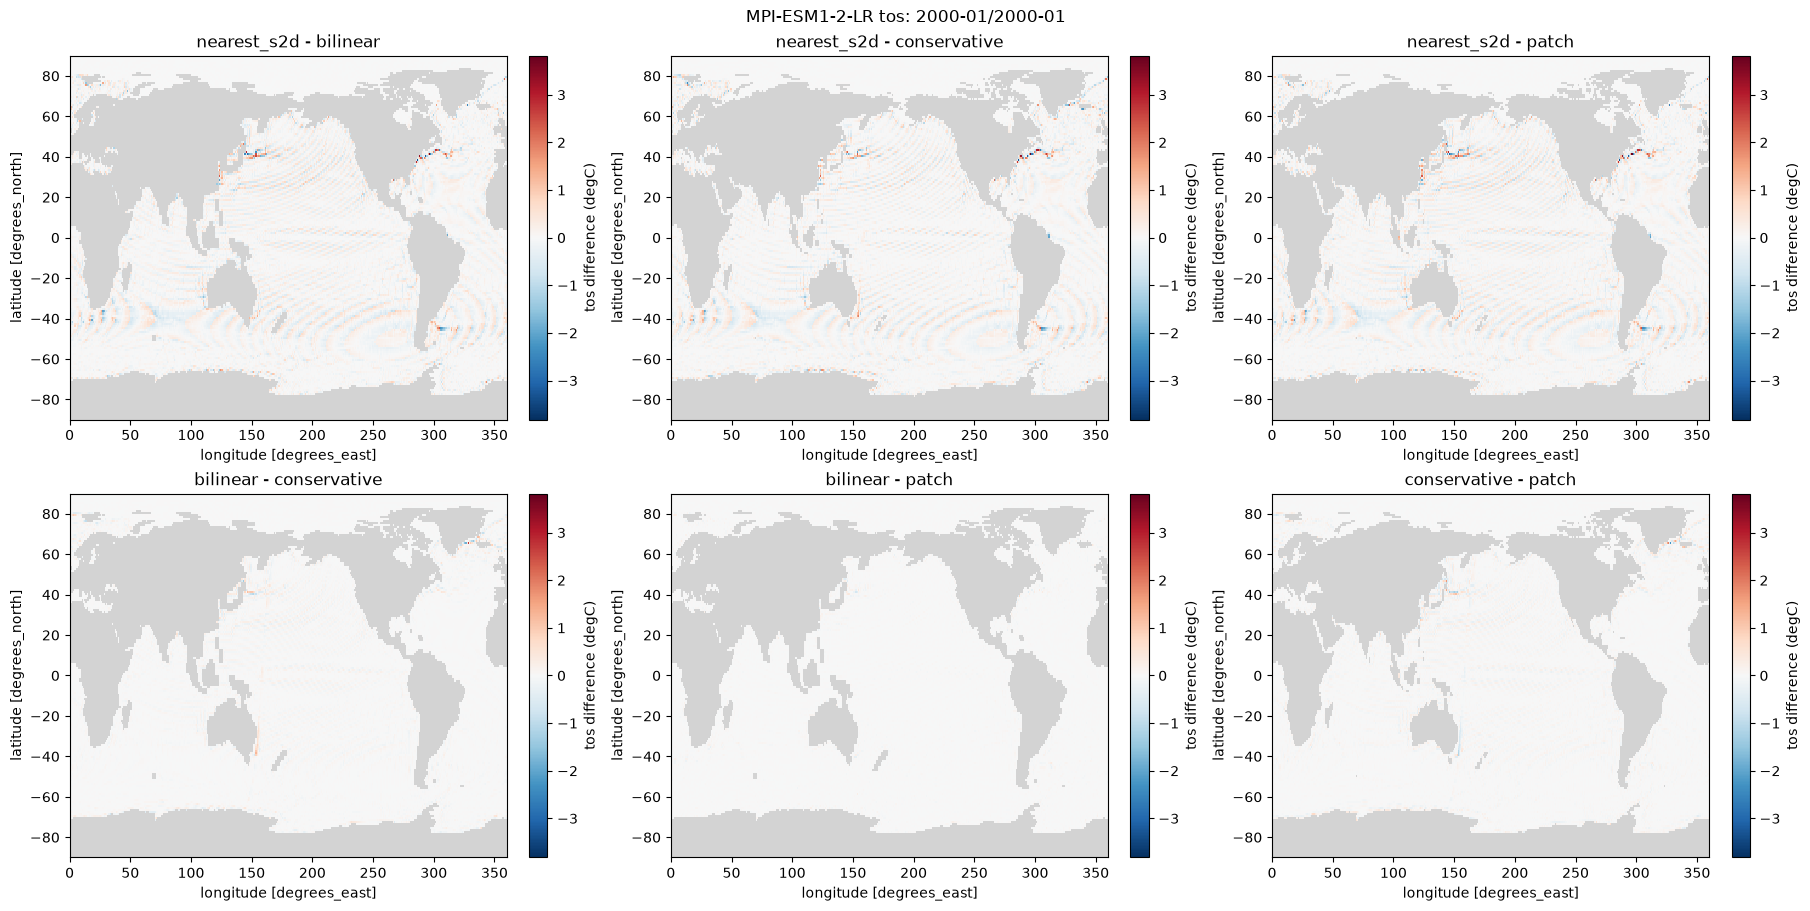

In [6]:
test_ocean_case('MPI-ESM1-2-LR tos', include_native=True)

,method,finite_cells,minimum,maximum
0,nearest_s2d,42320,-1.885377,31.697542
1,bilinear,40675,-1.881288,31.472113
2,conservative,41594,-1.885014,31.381258
3,patch,42300,-1.900879,31.422720


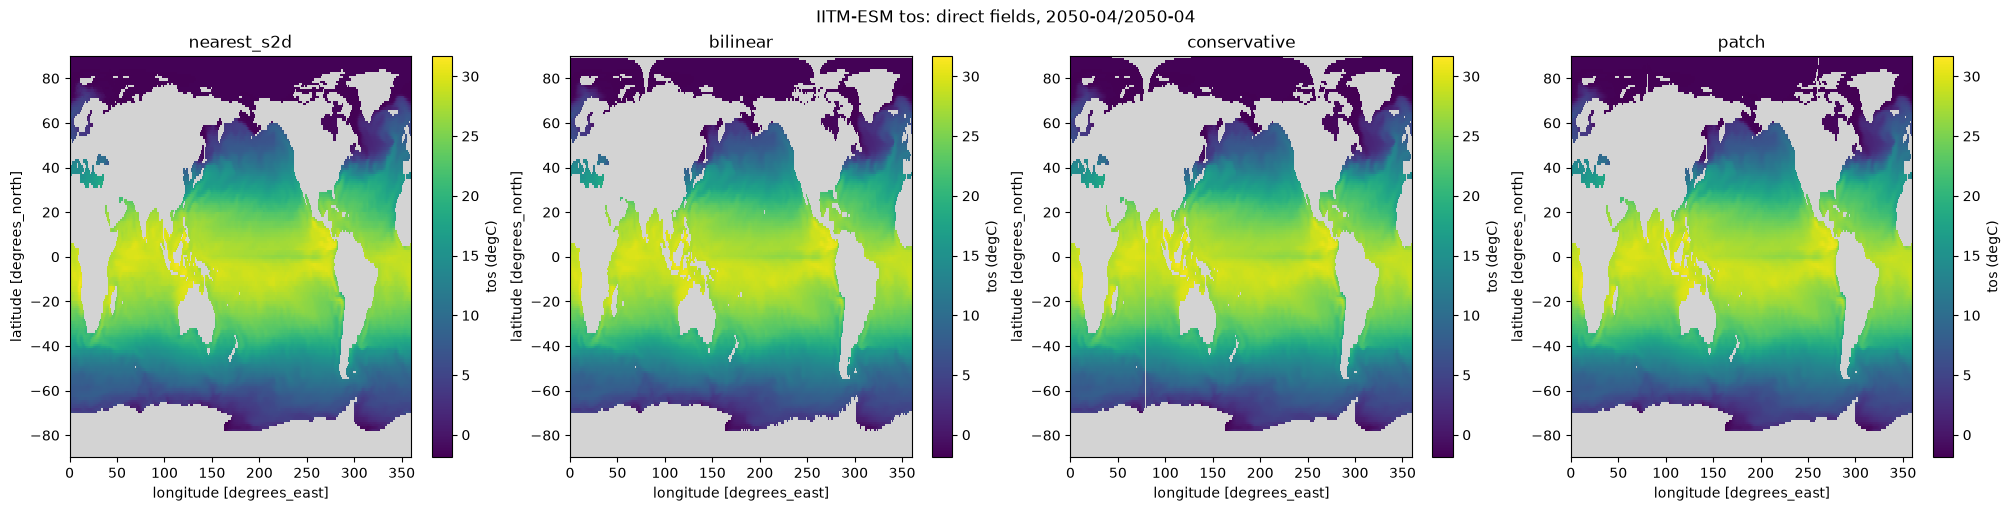

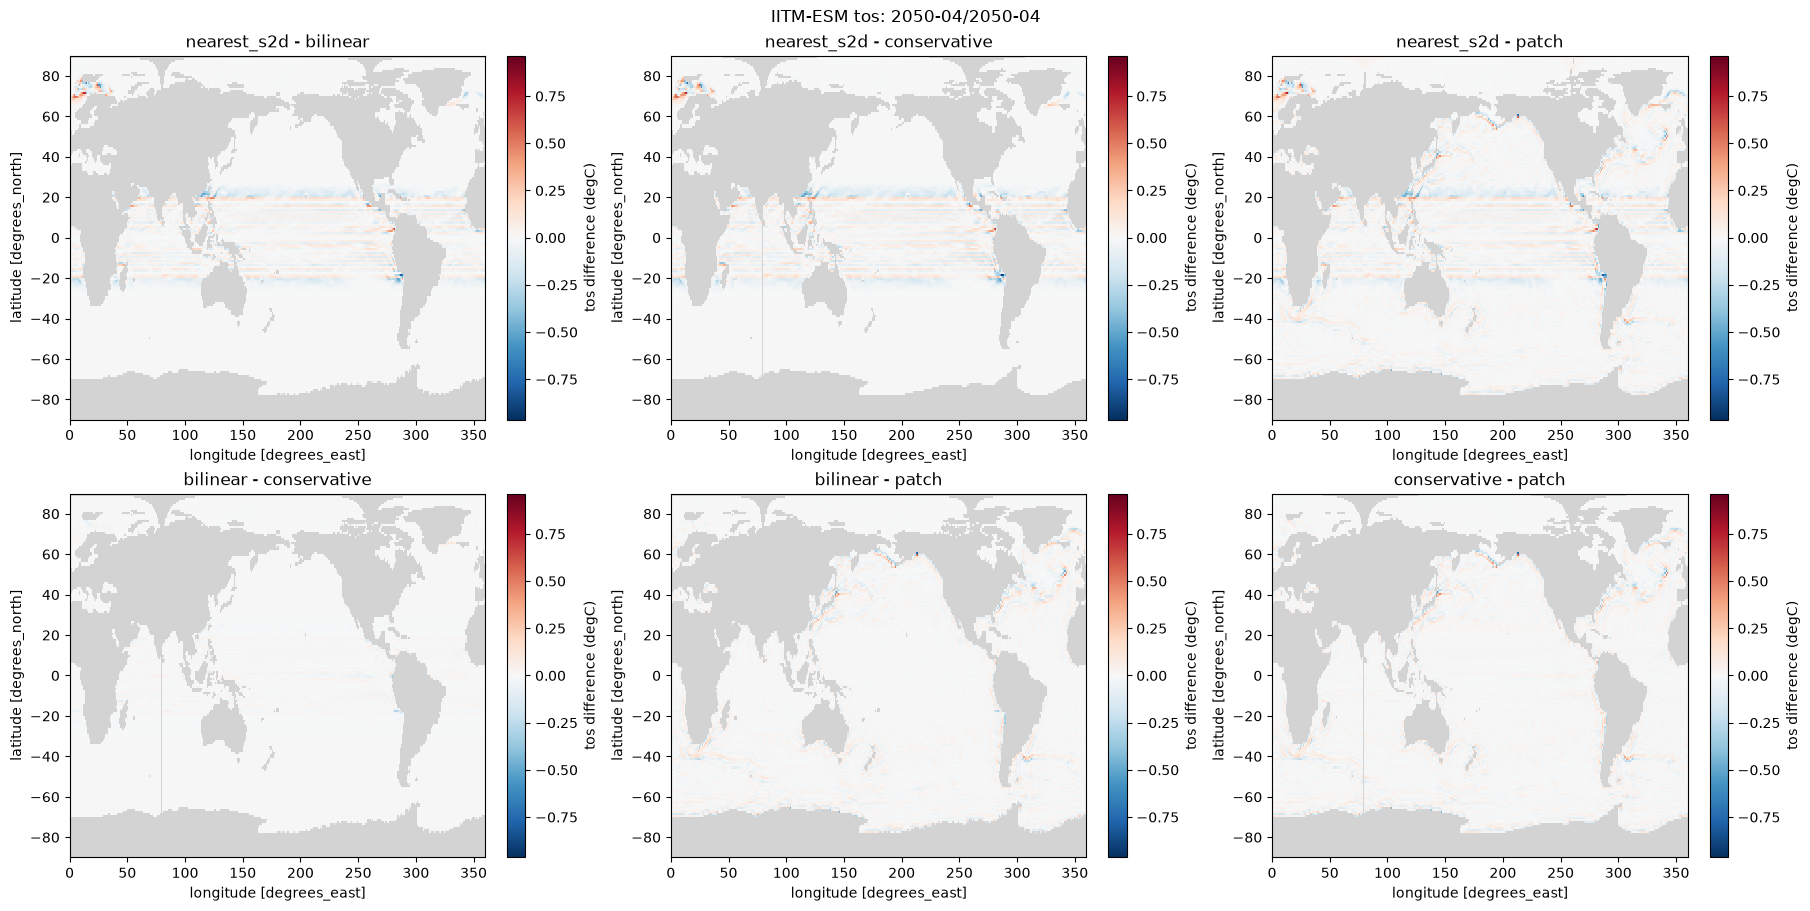

In [17]:
test_ocean_case('IITM-ESM tos')

### Does choosing the bundled mask grid actually mask land?

Compare nearest-neighbour MPI output on `custom_grid='0.5'` and `0pt5deg_lsm`. Normalize the longitude frame and require exact coordinates before comparing. Download the matching fractional land mask from roocs-grids for diagnostics only. A cell is counted as reference land when `sftlf >= 0.5`; coastlines can differ from the model's. No interpolation or nearest-coordinate matching of the mask is performed. Local post-masking is explicitly separate from the remote result.

,result,finite_cells,finite_on_reference_land
0,custom 0.5 (remote),170694,7253
1,0pt5deg_lsm (remote),170694,7253
2,0pt5deg_lsm + LOCAL post-mask,163441,0


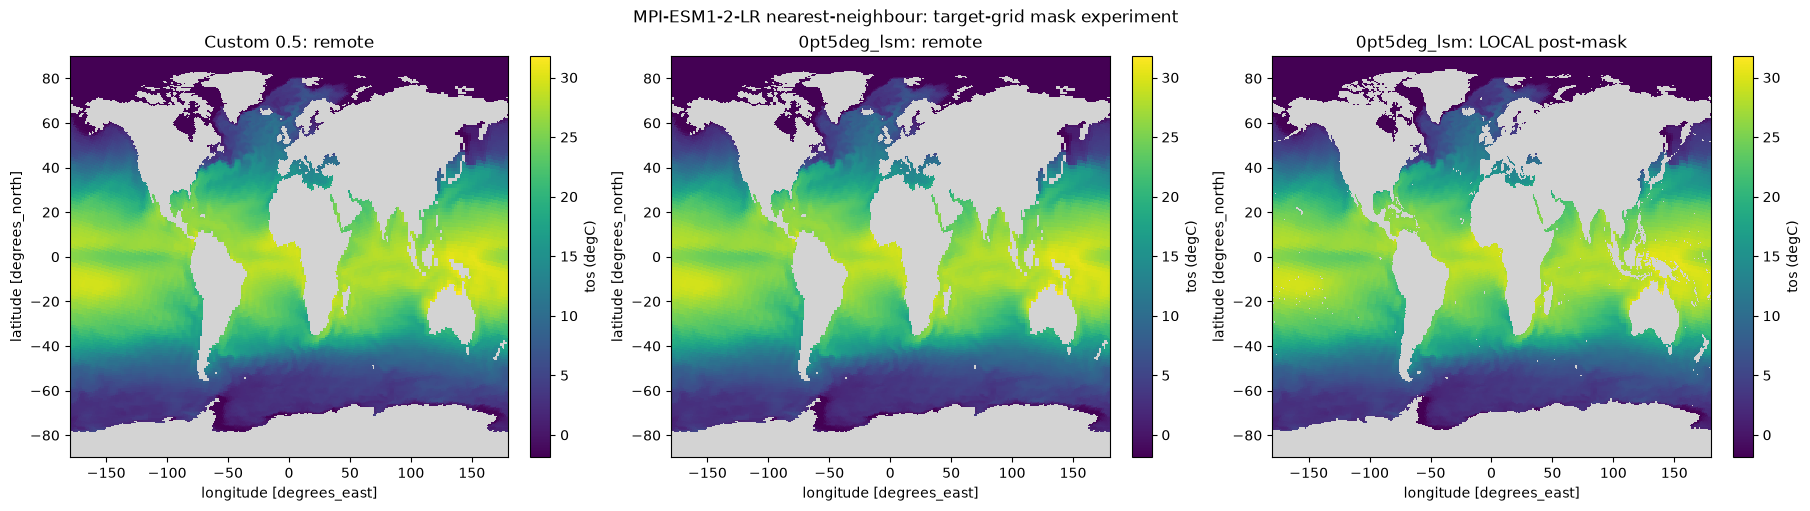

In [7]:
def canonical_ocean_grid(field):
    return field.assign_coords(lon=((field.lon + 180) % 360) - 180).sortby('lon').sortby('lat')

plain_half_degree = ocean_regrid('MPI-ESM1-2-LR tos', 'nearest_s2d', 'custom', '0.5')
bundled_mask_grid = ocean_regrid('MPI-ESM1-2-LR tos', 'nearest_s2d', '0pt5deg_lsm')
mask_url = 'https://raw.githubusercontent.com/roocs/roocs-grids/main/roocs_grids/grids/land_sea_mask_05degree.nc4'
land_fraction = canonical_ocean_grid(read_netcdf_url(mask_url).sftlf)
if not bool(np.isfinite(land_fraction).all()) or float(land_fraction.min()) < 0 or float(land_fraction.max()) > 1:
    raise ValueError('Expected a finite fractional reference mask in [0, 1]')
plain, bundled, land_fraction = xr.align(
    canonical_ocean_grid(plain_half_degree.tos.isel(time=0)),
    canonical_ocean_grid(bundled_mask_grid.tos.isel(time=0)),
    land_fraction, join='exact',
)
if plain.attrs.get('units') != bundled.attrs.get('units'):
    raise ValueError('Temperature units differ between target-grid experiments')
reference_land = land_fraction >= 0.5
locally_masked = bundled.where(~reference_land)
coverage = pd.DataFrame([
    {'result': name, 'finite_cells': int(np.isfinite(field).sum().item()),
     'finite_on_reference_land': int((np.isfinite(field) & reference_land).sum().item())}
    for name, field in [('custom 0.5 (remote)', plain), ('0pt5deg_lsm (remote)', bundled),
                        ('0pt5deg_lsm + LOCAL post-mask', locally_masked)]
])
display(coverage)
print('Finite/missing-mask disagreements:', int((np.isfinite(plain) != np.isfinite(bundled)).sum().item()))
target_difference = bundled - plain
print('Maximum absolute difference on common valid cells:', float(abs(target_difference).max(skipna=True).item()))
print('Reference-land cells:', int(reference_land.sum().item()), '/', reference_land.size)
assert int((np.isfinite(locally_masked) & reference_land).sum().item()) == 0

figure, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
vmin = min(float(plain.min().item()), float(bundled.min().item()))
vmax = max(float(plain.max().item()), float(bundled.max().item()))
for axis, (title, field) in zip(axes, [
    ('Custom 0.5: remote', plain), ('0pt5deg_lsm: remote', bundled),
    ('0pt5deg_lsm: LOCAL post-mask', locally_masked),
]):
    axis.set_facecolor('lightgrey')
    field.plot(ax=axis, vmin=vmin, vmax=vmax, cmap='viridis',
               cbar_kwargs={'label': f'tos ({bundled.attrs.get("units")})'})
    axis.set_title(title)
figure.suptitle('MPI-ESM1-2-LR nearest-neighbour: target-grid mask experiment')
plt.show()

### Ocean test observations

- All four methods completed for MPI-ESM1-2-LR January 2000 and IITM-ESM April 2050 on `1deg`; their pairwise maps are saved above. Completion alone does not establish scientific correctness or conservation.
- The remote output metadata reports `regrid_tool = xESMF_v0.9.2`. This identifies the reported regridding tool, not the complete deployed clisops version or the status of all fixes in D.2.1.11.
- For MPI nearest-neighbour at 0.5 degrees, the custom grid and `0pt5deg_lsm` had exactly matching coordinates after longitude-frame normalization, identical finite/missing patterns, and maximum absolute difference **0.0 degC** on common valid cells. Both contained **7,253** finite values over reference-land cells (`sftlf >= 0.5`). Thus merely selecting `_lsm` did not produce the reference land exclusion in this experiment.
- Applying the downloaded reference mask **locally after regridding** reduced finite cells from **170,694 to 163,441**, with zero finite values remaining on reference land. The output was not sent back to Rook. This demonstrates post-masking only, not mask-aware interpolation or repaired ocean-grid geometry.
- The tested service interface exposed no input for a chosen mask file or `mask='land'`. To control masking during weight generation, the server/wrapper would need to expose and forward that capability, or regridding would need to be run locally with clisops and a compatible target grid containing the intended mask. Local mask download is needed only for a local workflow or diagnostics, not to choose the server's bundled target grid.

These conclusions apply to the datasets, dates, grids, reference coastline and service tested here. In particular, the unstructured AWI ocean-grid masking described in D.2.1.11 remains unverified.

## Further ocean-grid edge cases

D.2.1.10 pp. 9-12 documents halos, collapsed/oversized cells and missing coordinates. These tests use its NorESM2-MM `simass` SSP126 dataset (p. 10, Figure 2) and EC-Earth3-Veg `deptho` SSP245 dataset (p. 11, Figure 3), rather than treating a `tos` field as a substitute. `simass` is sampled in April 2050; `deptho` is a fixed field and is requested without a time filter. The PDF figures do not specify a time slice, so identical maps to those figures are not expected.

Each comparison includes the original native field alongside the regridded fields on one colour scale, followed by differences between methods on the common target grid. Native source-centre plots do not reconstruct cell boundaries; gaps between markers are not necessarily missing values.

Native-grid diagnostics cover these cases and the MPI/IITM examples: non-finite/out-of-range latitude coordinates, duplicate centres after rounding to six decimals, coordinate extents, bounds availability, cells with fewer than three unique finite vertices, and unusually wide cells. Longitude width is the shortest circular arc containing the vertices, independent of whether the centre exists. This handles the longitude seam but does not establish polygon connectivity or validity. The 50-degree span diagnostic is motivated by the >50-degree cell described on p. 10; it is a screening flag, not proof of invalid geometry. Duplicate centres are not automatically proven halos. These are diagnostics of the subset delivered by Rook, which may already have processed source metadata.

Output checks include exact `1deg` coordinates, expected dimensions, source/output units, infinities, finite coverage, negative values, and departures from the native data range (numerical tolerance: `1e-6 * max(1, abs(source minimum), abs(source maximum))`). Values outside the source range are reported, not automatically labelled erroneous. Ice-mass zero is physically meaningful and is **not** treated as missing. Pairwise plots use the common valid cells and do not show cells missing in just one method.

**Method scope:** these cases compare `nearest_s2d`, `bilinear`, and `conservative`. A NorESM2 `simass` `patch` request did not complete during the test, so its outcome is unknown, not a confirmed algorithm failure. It is not automatically resubmitted below. `patch` is not requested for the fixed-field case; the `tos` patch tests remain available.

A final reference-land coverage table and map address D.2.1.10 section 3.10 and D.2.1.11 section 2.3. The generic land mask is a coastline diagnostic, not model-specific truth or a test of conservation. No area-integral conservation claim is made without native cell areas and matching integration domains.

**Limitations:** the inspected C3S CMIP6 catalog (v20260203) has no AWI-CM-1-1-MR/AWI-ESM-1-1-LR `tos`, BCC-CSM2-MR `tos`, GFDL-OM4p5B `volcello`, GFDL-ESM4 `mlotst`, or IITM-ESM `thetao`. Thus the reports' unstructured-grid mask case, BCC CF-identification case, GFDL unmasked-coordinate case, and exact 1pctCO2 longitude examples remain untested. Staggered vector regridding and the CORDEX-specific fixes are outside these scalar-ocean tests. Native longitude diagnostics below can reveal related extent issues but are not substitutes for those exact unavailable experiments.

In [5]:
ocean_cases.update({
    'NorESM2-MM simass edge case': {
        'variable': 'simass', 'time_range': '2050-04/2050-04',
        'methods': ['nearest_s2d', 'bilinear', 'conservative'],
        'dataset_id': 'c3s-cmip6.ScenarioMIP.NCC.NorESM2-MM.ssp126.r1i1p1f1.SImon.simass.gn.v20191108',
        'results': {},
    },
    'EC-Earth3-Veg deptho edge case': {
        'variable': 'deptho', 'time_range': None,
        'methods': ['nearest_s2d', 'bilinear', 'conservative'],
        'dataset_id': 'c3s-cmip6.ScenarioMIP.EC-Earth-Consortium.EC-Earth3-Veg.ssp245.r5i1p1f1.Ofx.deptho.gn.v20200312',
        'results': {},
    },
})
edge_native = {}
edge_grid_rows = []
edge_output_rows = []

def diagnose_ocean_grid(case_name, dataset):
    latitude = dataset.cf.coordinates.get('latitude', [])
    longitude = dataset.cf.coordinates.get('longitude', [])
    if len(latitude) != 1 or len(longitude) != 1:
        raise ValueError(f'{case_name}: ambiguous/missing CF coordinates: {latitude}, {longitude}')
    lat, lon = xr.broadcast(dataset[latitude[0]], dataset[longitude[0]])
    valid = np.isfinite(lat.values) & np.isfinite(lon.values)
    if not valid.any():
        raise ValueError(f'{case_name}: no finite native coordinate pairs')
    centres = np.round(np.column_stack([
        lat.values[valid], ((lon.values[valid] + 180) % 360) - 180,
    ]), 6)
    row = {
        'case': case_name, 'native_shape': str(lat.shape),
        'nonfinite_coordinate_pairs': int((~valid).sum()),
        'latitude_outside_90': int((np.isfinite(lat) & (abs(lat) > 90)).sum().item()),
        'duplicate_centres_6dp': len(centres) - len(np.unique(centres, axis=0)),
        'longitude_min': float(lon.min(skipna=True).item()),
        'longitude_max': float(lon.max(skipna=True).item()),
        'latitude_min': float(lat.min(skipna=True).item()),
        'latitude_max': float(lat.max(skipna=True).item()),
    }
    lat_bounds = dataset[latitude[0]].attrs.get('bounds')
    lon_bounds = dataset[longitude[0]].attrs.get('bounds')
    row['bounds_available'] = lat_bounds in dataset and lon_bounds in dataset
    if row['bounds_available']:
        lat_b, lon_b = xr.broadcast(dataset[lat_bounds], dataset[lon_bounds])
        vertex_dims = [dim for dim in lat_b.dims if dim not in lat.dims]
        if len(vertex_dims) != 1:
            raise ValueError(f'{case_name}: unexpected native bounds dimensions: {lat_b.dims}')
        vertex_dim = vertex_dims[0]
        lat_b = lat_b.transpose(*lat.dims, vertex_dim).values
        lon_b = lon_b.transpose(*lat.dims, vertex_dim).values
        finite_bounds = np.isfinite(lat_b).all(axis=-1) & np.isfinite(lon_b).all(axis=-1)
        corners = np.sort_complex(np.round(lat_b, 6) + 1j * np.round(((lon_b + 180) % 360) - 180, 6))
        unique_vertices = 1 + np.sum(corners[..., 1:] != corners[..., :-1], axis=-1)
        row['vertices_per_cell'] = lat_b.shape[-1]
        row['nonfinite_bound_cells'] = int((~finite_bounds).sum())
        row['fewer_than_3_unique_vertices'] = int(((unique_vertices < 3) & finite_bounds).sum())
        lat_span = np.ptp(lat_b, axis=-1)
        lon_angles = np.sort(lon_b % 360, axis=-1)
        lon_gaps = np.diff(np.concatenate([lon_angles, lon_angles[..., :1] + 360], axis=-1), axis=-1)
        lon_span = 360 - lon_gaps.max(axis=-1)
        row['latitude_span_over_50deg'] = int(((lat_span > 50) & finite_bounds).sum())
        row['longitude_span_over_50deg'] = int(((lon_span > 50) & finite_bounds).sum())
        row['max_latitude_span'] = float(lat_span[finite_bounds].max()) if finite_bounds.any() else np.nan
        row['max_longitude_span'] = float(lon_span[finite_bounds].max()) if finite_bounds.any() else np.nan
    return row

def run_documented_ocean_case(case_name):
    case = ocean_cases[case_name]
    native = ocean_native(case_name)
    edge_native[case_name] = native
    grid_row = diagnose_ocean_grid(case_name, native)
    edge_grid_rows.append(grid_row)
    display(pd.DataFrame([grid_row]).T)
    additional_regrid_cases[case_name] = case
    source_field = native[case['variable']]
    source_min = float(source_field.min(skipna=True).item())
    source_max = float(source_field.max(skipna=True).item())
    tolerance = 1e-6 * max(1, abs(source_min), abs(source_max))
    for method in case['methods']:
        result = ocean_regrid(case_name, method, '1deg')
        case['results'][method] = result
        field = result[case['variable']]
        expected_dims = ('time', 'lat', 'lon') if case['time_range'] is not None else ('lat', 'lon')
        if field.dims != expected_dims or field.sizes['lat'] != 180 or field.sizes['lon'] != 360:
            raise ValueError(f'{case_name}/{method}: unexpected output dimensions {field.sizes}')
        np.testing.assert_allclose(field.lat, np.arange(-89.5, 90, 1), rtol=0, atol=1e-8)
        np.testing.assert_allclose(field.lon, np.arange(0.5, 360, 1), rtol=0, atol=1e-8)
        if field.attrs.get('units') != source_field.attrs.get('units'):
            raise ValueError(f'{case_name}/{method}: native/output units differ')
        if bool(np.isinf(field).any()):
            raise ValueError(f'{case_name}/{method}: infinite output values')
        edge_output_rows.append({
            'case': case_name, 'method': method, 'units': field.attrs.get('units'),
            'finite_cells': int(np.isfinite(field).sum().item()),
            'source_min': source_min, 'source_max': source_max,
            'output_min': float(field.min(skipna=True).item()),
            'output_max': float(field.max(skipna=True).item()),
            'negative_cells': int((field < 0).sum().item()),
            'below_source_range': int((field < source_min - tolerance).sum().item()),
            'above_source_range': int((field > source_max + tolerance).sum().item()),
        })
    display(pd.DataFrame([row for row in edge_output_rows if row['case'] == case_name]))
    plot_case_differences(case_name, native_field=source_field)

,0
case,NorESM2-MM simass edge case
native_shape,"(384, 360)"
nonfinite_coordinate_pairs,39852
latitude_outside_90,0
duplicate_centres_6dp,0
longitude_min,0.003662
longitude_max,359.989471
latitude_min,-79.02993
latitude_max,89.757492
bounds_available,True


,case,method,units,finite_cells,source_min,source_max,output_min,output_max,negative_cells,below_source_range,above_source_range
0,NorESM2-MM simass edge case,nearest_s2d,kg m-2,42773,0.0,31949.681641,0.0,31949.681641,0,0,0
1,NorESM2-MM simass edge case,bilinear,kg m-2,41200,0.0,31949.681641,0.0,28994.107422,0,0,0
2,NorESM2-MM simass edge case,conservative,kg m-2,44879,0.0,31949.681641,0.0,21515.367188,0,0,0


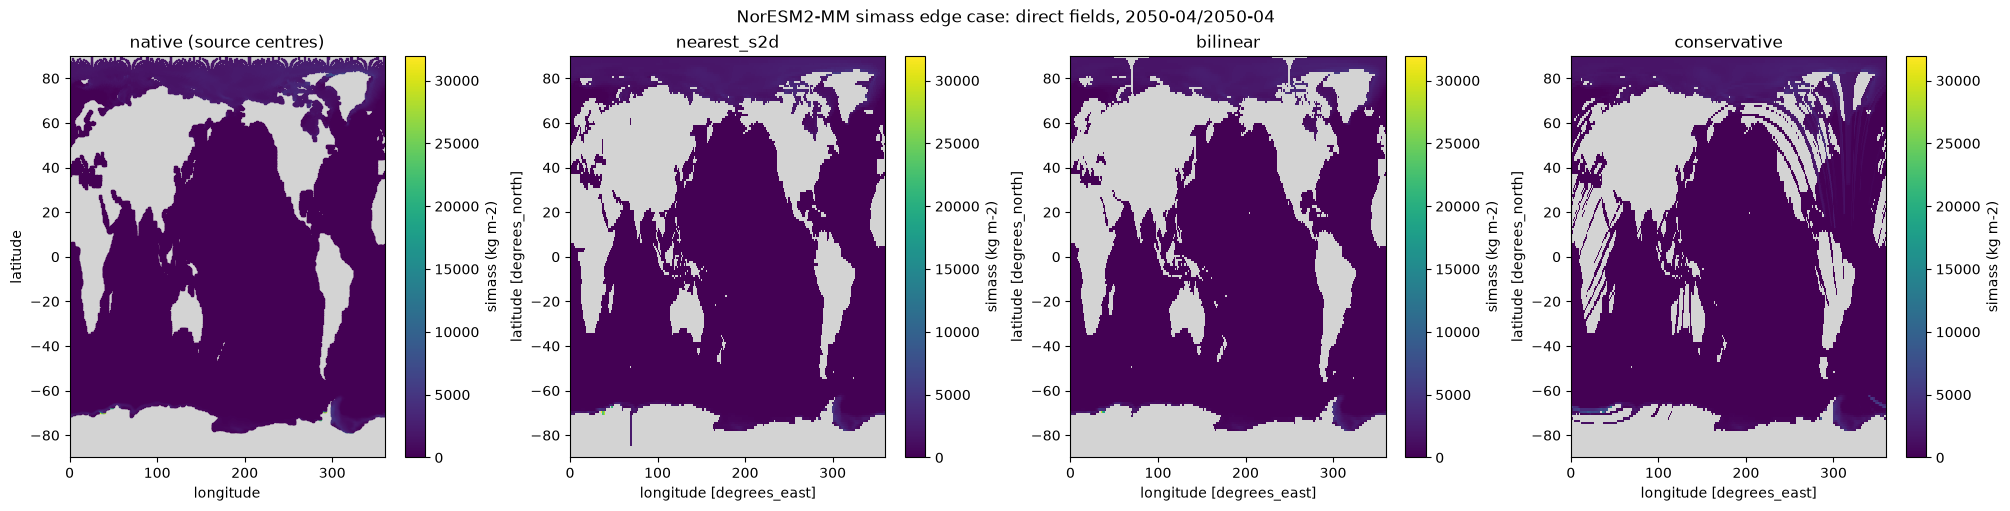

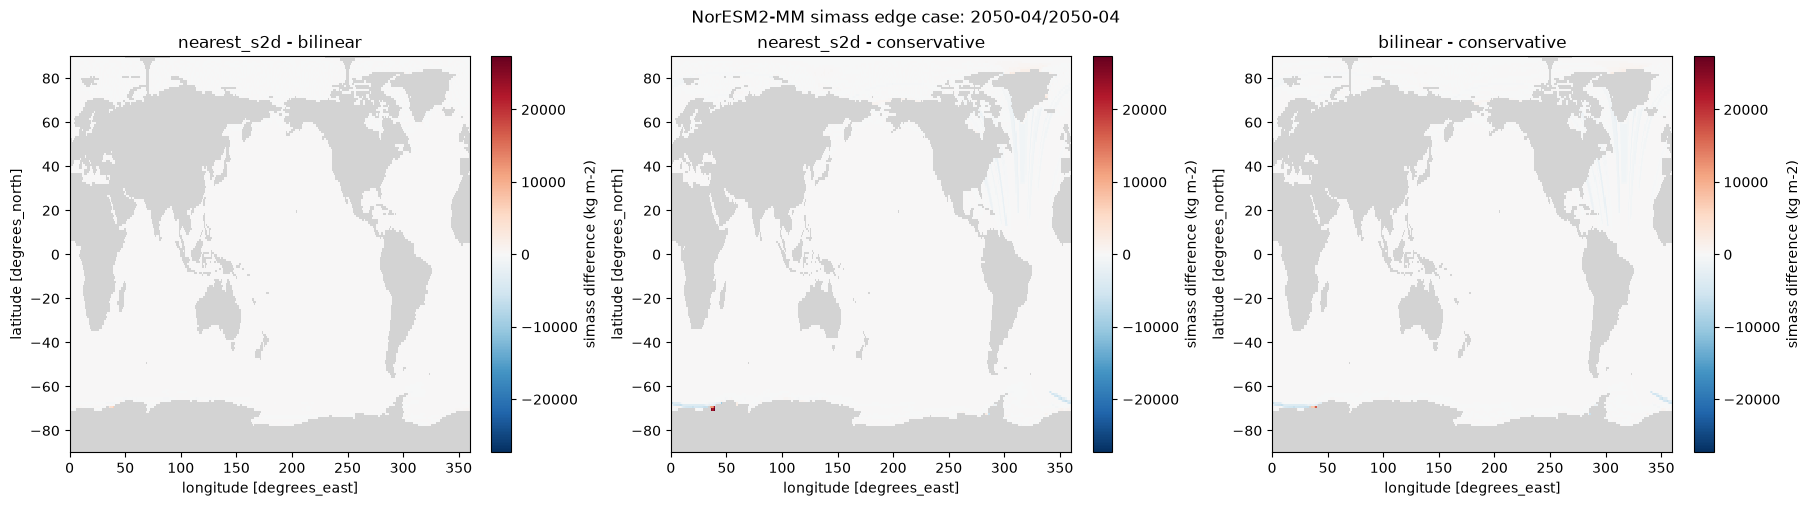

In [7]:
run_documented_ocean_case('NorESM2-MM simass edge case')

,0
case,EC-Earth3-Veg deptho edge case
native_shape,"(292, 362)"
nonfinite_coordinate_pairs,0
latitude_outside_90,0
duplicate_centres_6dp,1408
longitude_min,0.0
longitude_max,359.994925
latitude_min,-78.57995
latitude_max,89.74177
bounds_available,True


,case,method,units,finite_cells,source_min,source_max,output_min,output_max,negative_cells,below_source_range,above_source_range
0,EC-Earth3-Veg deptho edge case,nearest_s2d,m,64800,0.0,7660.0,0.0,7660.000000,0,0,0
1,EC-Earth3-Veg deptho edge case,bilinear,m,64077,0.0,7660.0,0.0,7301.812012,0,0,0
2,EC-Earth3-Veg deptho edge case,conservative,m,60417,0.0,7660.0,0.0,7295.059082,0,0,0


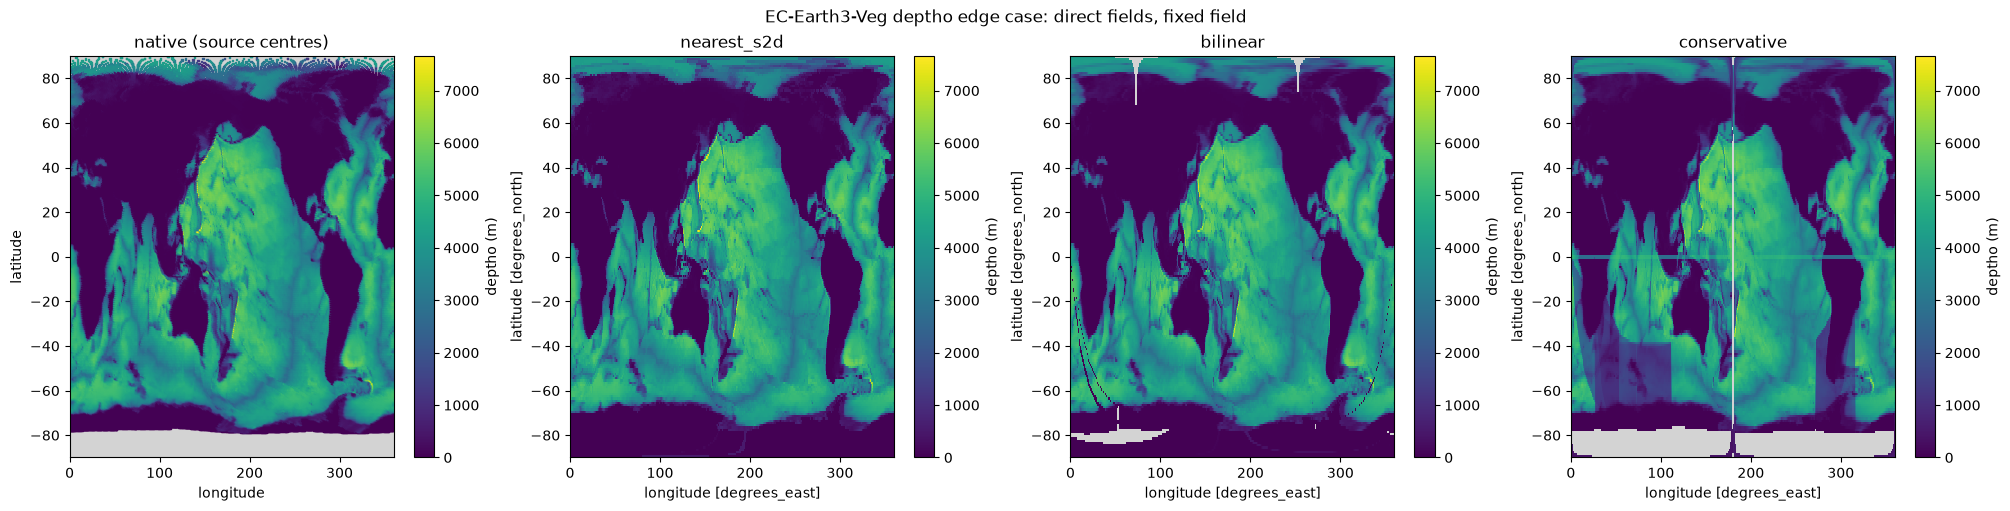

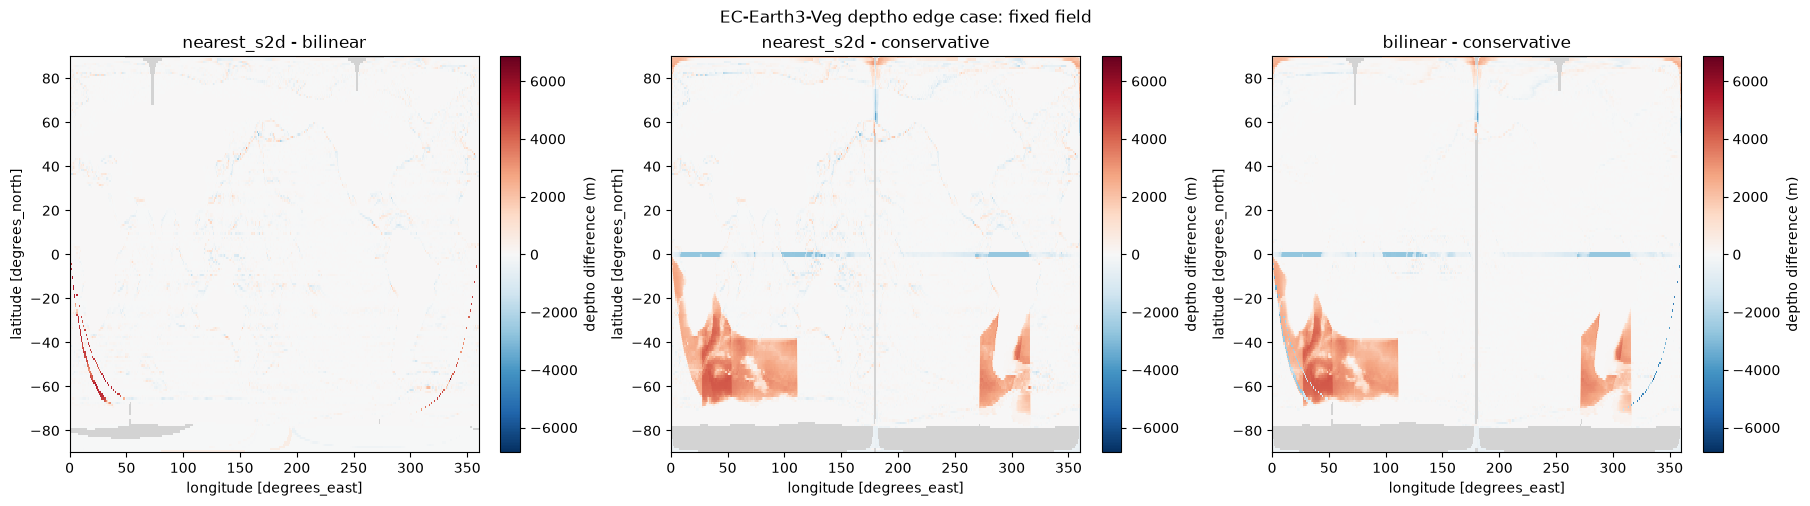

In [8]:
run_documented_ocean_case('EC-Earth3-Veg deptho edge case')

In [8]:
for case_name in ['MPI-ESM1-2-LR tos', 'IITM-ESM tos']:
    native = ocean_native(case_name)
    edge_native[case_name] = native
    edge_grid_rows.append(diagnose_ocean_grid(case_name, native))
    for method in regrid_methods:
        ocean_cases[case_name]['results'][method] = ocean_regrid(case_name, method, '1deg')
display(pd.DataFrame(edge_grid_rows).set_index('case').T)
display(pd.DataFrame(edge_output_rows))


case,NorESM2-MM simass edge case,EC-Earth3-Veg deptho edge case,MPI-ESM1-2-LR tos,IITM-ESM tos
native_shape,"(384, 360)","(292, 362)","(220, 256)","(200, 360)"
nonfinite_coordinate_pairs,39852,0,0,0
latitude_outside_90,0,0,0,0
duplicate_centres_6dp,0,1408,440,0
longitude_min,0.003662,0.0,0.007175,-279.980316
longitude_max,359.989471,359.994925,359.996041,79.980324
latitude_min,-79.02993,-78.57995,-83.96551,-81.5
latitude_max,89.757492,89.74177,89.726604,89.487862
bounds_available,True,True,True,False
vertices_per_cell,4.0,4.0,4.0,NaN


,case,method,units,finite_cells,source_min,source_max,output_min,output_max,negative_cells,below_source_range,above_source_range
0,NorESM2-MM simass edge case,nearest_s2d,kg m-2,42773,0.0,31949.681641,0.0,31949.681641,0,0,0
1,NorESM2-MM simass edge case,bilinear,kg m-2,41200,0.0,31949.681641,0.0,28994.107422,0,0,0
2,NorESM2-MM simass edge case,conservative,kg m-2,44879,0.0,31949.681641,0.0,21515.367188,0,0,0
3,EC-Earth3-Veg deptho edge case,nearest_s2d,m,64800,0.0,7660.000000,0.0,7660.000000,0,0,0
4,EC-Earth3-Veg deptho edge case,bilinear,m,64077,0.0,7660.000000,0.0,7301.812012,0,0,0
5,EC-Earth3-Veg deptho edge case,conservative,m,60417,0.0,7660.000000,0.0,7295.059082,0,0,0


,case,method,finite_reference_land,nonzero_reference_land,missing_reference_ocean
0,MPI-ESM1-2-LR tos,nearest_s2d,2277,2277,141
1,MPI-ESM1-2-LR tos,bilinear,927,927,968
2,MPI-ESM1-2-LR tos,conservative,2297,2297,120
3,MPI-ESM1-2-LR tos,patch,2283,2283,110
4,IITM-ESM tos,nearest_s2d,1902,1902,125
5,IITM-ESM tos,bilinear,1261,1261,1129
6,IITM-ESM tos,conservative,1883,1883,832
7,IITM-ESM tos,patch,1896,1896,139
8,NorESM2-MM simass edge case,nearest_s2d,2288,1098,58
9,NorESM2-MM simass edge case,bilinear,1167,573,510


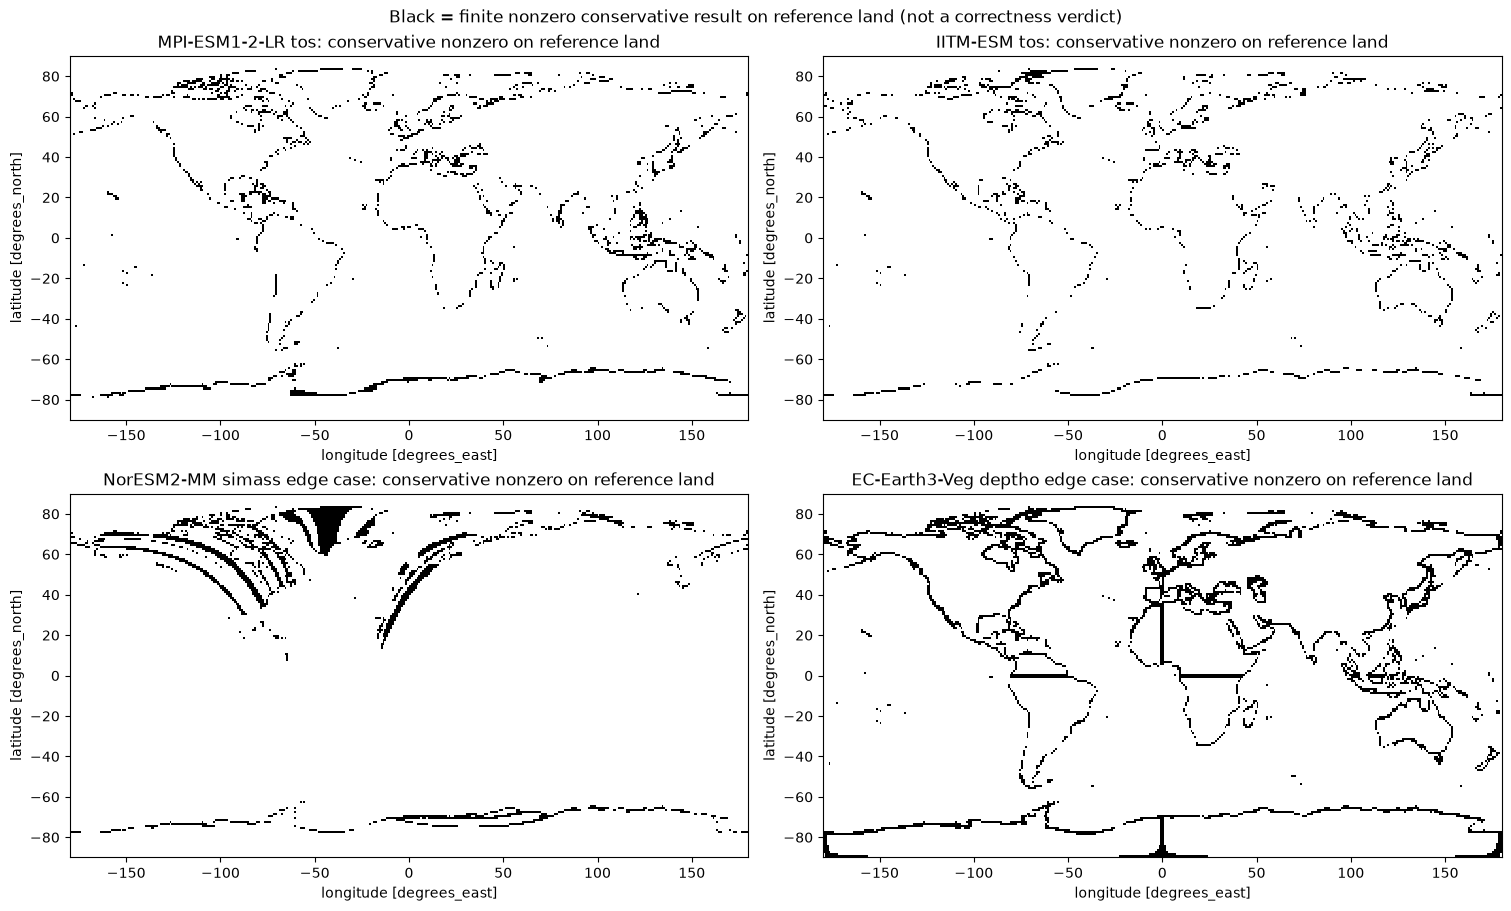

,case,comparison,units,common_valid,finite_mask_disagreements,mean_absolute_difference,rmse,max_absolute_difference
0,MPI-ESM1-2-LR tos,nearest_s2d - bilinear,degC,40502,2177,0.134701,0.227673,3.740678
1,MPI-ESM1-2-LR tos,nearest_s2d - conservative,degC,42586,227,0.119465,0.216230,3.820607
2,MPI-ESM1-2-LR tos,nearest_s2d - patch,degC,42548,299,0.136391,0.229931,3.814614
3,MPI-ESM1-2-LR tos,bilinear - conservative,degC,40502,2218,0.035175,0.071588,2.680727
4,MPI-ESM1-2-LR tos,bilinear - patch,degC,40502,2214,0.011285,0.023490,0.737225
5,MPI-ESM1-2-LR tos,conservative - patch,degC,42627,182,0.038391,0.075241,2.278359
6,IITM-ESM tos,nearest_s2d - bilinear,degC,40675,1645,0.018035,0.045734,0.803305
7,IITM-ESM tos,nearest_s2d - conservative,degC,41566,782,0.021036,0.050843,0.963934
8,IITM-ESM tos,nearest_s2d - patch,degC,42265,90,0.032837,0.058383,0.836411
9,IITM-ESM tos,bilinear - conservative,degC,40398,1473,0.003638,0.009260,0.348127


In [9]:
mask_1deg_url = 'https://raw.githubusercontent.com/roocs/roocs-grids/main/roocs_grids/grids/land_sea_mask_1degree.nc4'
reference_fraction_1deg = read_netcdf_url(mask_1deg_url).sftlf
if not bool(np.isfinite(reference_fraction_1deg).all()) or float(reference_fraction_1deg.min()) < 0 or float(reference_fraction_1deg.max()) > 1:
    raise ValueError('Expected finite fractional land mask in [0, 1]')

def canonical_edge_grid(field):
    return field.assign_coords(lon=((field.lon + 180) % 360) - 180).sortby('lon').sortby('lat')

edge_land_rows = []
figure, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
for axis, (case_name, case) in zip(axes.flat, ocean_cases.items()):
    for method, result in case['results'].items():
        field = result[case['variable']]
        if 'time' in field.dims:
            field = field.isel(time=0)
        field, fraction = xr.align(canonical_edge_grid(field), canonical_edge_grid(reference_fraction_1deg), join='exact')
        reference_land = fraction >= 0.5
        finite_on_land = np.isfinite(field) & reference_land
        edge_land_rows.append({
            'case': case_name, 'method': method,
            'finite_reference_land': int(finite_on_land.sum().item()),
            'nonzero_reference_land': int((finite_on_land & (field != 0)).sum().item()),
            'missing_reference_ocean': int(((~np.isfinite(field)) & (~reference_land)).sum().item()),
        })
        if method == 'conservative':
            (finite_on_land & (field != 0)).astype(int).plot(ax=axis, vmin=0, vmax=1, cmap='Greys', add_colorbar=False)
            axis.set_title(f'{case_name}: conservative nonzero on reference land')
display(pd.DataFrame(edge_land_rows))
figure.suptitle('Black = finite nonzero conservative result on reference land (not a correctness verdict)')
plt.show()

edge_pair_rows = []
for case_name, case in ocean_cases.items():
    for method_a, method_b in combinations(case['results'], 2):
        field_a, field_b = xr.align(case['results'][method_a][case['variable']],
                                   case['results'][method_b][case['variable']], join='exact')
        finite_a, finite_b = np.isfinite(field_a), np.isfinite(field_b)
        common = finite_a & finite_b
        if int(common.sum().item()) == 0:
            raise ValueError(f'{case_name}: no common valid values for {method_a}/{method_b}')
        difference = (field_a - field_b).where(common)
        edge_pair_rows.append({
            'case': case_name, 'comparison': f'{method_a} - {method_b}',
            'units': field_a.attrs.get('units'),
            'common_valid': int(common.sum().item()),
            'finite_mask_disagreements': int((finite_a != finite_b).sum().item()),
            'mean_absolute_difference': float(abs(difference).mean(skipna=True).item()),
            'rmse': float(np.sqrt((difference**2).mean(skipna=True)).item()),
            'max_absolute_difference': float(abs(difference).max(skipna=True).item()),
        })
display(pd.DataFrame(edge_pair_rows))

### Ocean edge-case findings

**The documented conservative-remapping artifact patterns remain visible in these tests.** All six nearest/bilinear/conservative requests completed, with the expected 1-degree coordinates, unchanged units, no infinities, no negative values, and no departures from the native value range. Those checks alone would therefore miss the spatial problems shown in the maps.

| Case | Native-grid evidence | Regridded observations |
| --- | --- | --- |
| NorESM2-MM `simass`, D.2.1.10 Figure 2 | 39,852 non-finite coordinate pairs; 39,672 cells with fewer than three unique finite vertices; 1,880 cells with latitude span >50 degrees | The conservative map shows broad streaks across land resembling the report's artifact pattern. Nearest-versus-conservative RMSE on common valid cells is 406.87 kg m-2; mask patterns disagree in 2,586 cells. |
| EC-Earth3-Veg `deptho`, Figure 3 | 834 cells with fewer than three unique finite vertices and 1,408 duplicate centres | Conservative output shows strong meridional/equatorial and block-like features. Nearest-versus-conservative RMSE on common valid cells is 779.07 m; mask patterns disagree in 4,383 cells. Native depth is zero in many land cells, so finite coverage alone is not leakage evidence. |
| MPI-ESM1-2-LR `tos`, halo example | 440 duplicate centres and 25 cells with fewer than three unique finite vertices | This supports the presence of problematic geometry, but does not test halo removal or adaptive-masking toggles; the service exposes neither control. |
| IITM-ESM `tos`, Figure 4 / related longitude-frame issue | Native longitudes span -279.980316 to 79.980324 degrees; no CF-linked bounds were delivered | The earlier remapping completes on a standard target grid despite this source longitude frame. It is not the exact unavailable `thetao` 1pctCO2 example. |

The reference-land diagnostic finds **2,525 nonzero conservative `simass` cells** on reference land versus **1,098 for nearest** (bilinear: 573). This is consistent with the visibly extensive streaks, while individual coastal differences may reflect mask/model coastline mismatch. The corresponding `deptho` counts are 4,566 conservative, 2,532 nearest and 7,611 bilinear; counts alone cannot rank scientific accuracy. No mask was applied to the remote requests in this section.

The NorESM2 `patch` attempt remains **incomplete** and is excluded from these comparisons. The unavailable-dataset and unstructured-grid gaps listed above remain **untested**, not passes. These single-slice diagnostics reproduce warning signs; they do not establish conservation, a generally best method, or complete validation of either deliverable.